In [5]:
import mne
from anlffr.helper import biosemi2mne as bs
from anlffr.preproc import find_blinks
from matplotlib import pyplot as plt
from mne import compute_proj_epochs
from mne import concatenate_epochs
import pylab as pl
import numpy as np
import os
import fnmatch
from scipy.fft import fft
from scipy.signal import find_peaks
import gc 
# from autoreject import AutoReject

In [6]:
fpath = "/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/"
subj = 'SP017'
resultsdir = 'results/'

In [7]:
# lefts = []
# rights = []
# cues = []

# event_counts = {2: 0, 3: 0, 4: 0, 5: 0, 6: 0}

# channels_to_drop = ['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']

# bdfs = fnmatch.filter(os.listdir(fpath), subj + '_Att*.bdf')
# print(bdfs)

# for k, bdf in enumerate(bdfs):
#     bdf_fullpath = os.path.join(fpath, bdf)
# #         raw, eves = bs.importbdf(bdf_fullpath, hptsname='biosemi10_20.hpts')
#     raw, eves = bs.importbdf(bdf_fullpath, hptsname='biosemi10_20.hpts')
#     total = raw.times[-1]
#     end_time = total - 120
#     raw = raw.crop(tmin=0, tmax=end_time)
#     raw.notch_filter(np.arange(60, 241, 60), filter_length='auto', fir_design='firwin')
#     raw.filter(1, 40)

#     blinks = find_blinks(raw, ch_name=['Fp1'])
#     if k == 0:
#         epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
#                                     reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
#         blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=4)
#     raw.add_proj(blink_proj)

#     raw.plot_projs_topomap()
#     # raw.del_proj(1)
#     # raw.del_proj(2)
#     # raw.apply_proj()

In [8]:
# raw.plot_projs_topomap()

In [ ]:
lefts = []
rights = []
# cues = []
leads = []
lags = []

event_counts = {1:0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0}

channels_to_drop = ['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']

bdfs = fnmatch.filter(os.listdir(fpath), subj + '_Att*.bdf')
if subj == 'HL012':
    bdfs = ['HL012_AttentionTask.bdf', 'HL012_AttentionTask+004.bdf', 'HL012_AttentionTask+005.bdf', 'HL012_AttentionTask+006.bdf', 'HL012_AttentionTask+002.bdf', 'HL012_AttentionTask+003.bdf', 'HL012_AttentionTask+001.bdf']
if subj == 'HL025':
    bdfs = ['HL025_AttentionTask+002.bdf', 'HL025_AttentionTask+003.bdf', 'HL025_AttentionTask+004.bdf']
if subj == 'SP014':
    bdfs = ['SP014_AttentionTask.bdf', 'SP014_AttentionTask+004.bdf', 'SP014_AttentionTask+002.bdf', 'SP014_AttentionTask+003.bdf', 'SP014_AttentionTask+001.bdf']
    ###ABR has been recorded with the same name as Attention - check to make sure it's written somewhere 
print(bdfs)

for k, bdf in enumerate(bdfs):
    if bdf == 'HL008_AttentionTask+004.bdf':
        bdf_fullpath = os.path.join(fpath, bdf)
        raw, eves = bs.importbdf(bdf_fullpath, hptsname='biosemi10_20.hpts')
        total = raw.times[-1]
        end_time = total - 120
        raw = raw.crop(tmin=0, tmax=end_time)
    else:
        bdf_fullpath = os.path.join(fpath, bdf)
        raw, eves = bs.importbdf(bdf_fullpath, hptsname='biosemi10_20.hpts') 
    print(f'Running file: {bdf}')
    raw.notch_filter(
    np.arange(60, 241, 60),
    filter_length='auto',
    fir_design='firwin',
    method='fir'
    )
    raw.filter(1., 40., fir_design='firwin')

    if subj == 'SP004' or subj == 'SP019':
        raw.drop_channels(channels_to_drop)

    blinks = find_blinks(raw, ch_name=['Fp1'])
    if subj in ['HR', 'SP004', 'HL004', 'HL010', 'HL022', 'HL031']:
        if k == 0:
            epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                       reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
            blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=2)
        
        raw.add_proj(blink_proj)
        #raw.del_proj(1)
        raw.apply_proj()
    
    elif subj == 'HL022':
        if k == 0:
            epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                       reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
            blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=4)
        
        raw.add_proj(blink_proj)
        raw.del_proj(1)
        raw.del_proj(2)
        raw.apply_proj()

    else:
        if k == 0:
            epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                       reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
            blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=3)
        
        raw.add_proj(blink_proj)
        raw.del_proj(1)
        raw.apply_proj()
        
    for event_id in [2, 3, 4, 5, 6]:
        event_counts[event_id] += np.sum(eves[:, 2] == event_id)

    events_left = [7,8]
    events_left_use = [event_left for event_left in events_left if event_left in eves[:,2]]
    
    events_right = [9,10]
    events_right_use = [event_right for event_right in events_right if event_right in eves[:,2]]

    events_lead = [7,9]
    events_lead_use = [event_lead for event_lead in events_lead if event_lead in eves[:,2]]

    events_lag = [8,10]
    events_lag_use = [event_lag for event_lag in events_lag if event_lag in eves[:,2]]
    
    # events_cue = [7,8,9,10]
    # events_cues_use = [event_cue for event_cue in events_cue if event_cue in eves[:, 2]]

    if events_left_use:
        epochs_left = mne.Epochs(raw, eves, event_id=events_left_use, baseline=(-0.5, 0.0), proj=True,
                        tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
    if events_right_use:
        epochs_right = mne.Epochs(raw, eves, event_id=events_right_use, baseline=(-0.5, 0.0), proj=True,
                        tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
    if events_lead_use:
            epochs_lead = mne.Epochs(raw, eves, event_id=events_lead_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
    if events_lag_use:
            epochs_lag = mne.Epochs(raw, eves, event_id=events_lag_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
    
    # if events_cues_use:
    #     epochs_cue = mne.Epochs(raw, eves, event_id=events_cues_use, baseline=(-0.5, 0), proj=True,
    #                     tmin=-0.5, tmax=5, reject=dict(eeg=200e-6), preload=True) 
        
    lefts += [epochs_left, ]
    rights += [epochs_right, ]
    leads += [epochs_lead, ]
    lags += [epochs_lag, ]
    # cues += [epochs_cue, ]


left = concatenate_epochs(lefts)
right = concatenate_epochs(rights)   
# cue = concatenate_epochs(cues) 
lead = concatenate_epochs(leads)
lag = concatenate_epochs(lags) 

# ar = AutoReject()

# left_clean = ar.fit_transform(left)
# right_clean = ar.fit_transform(right)
# lead_clean = ar.fit_transform(lead)
# lag_clean = ar.fit_transform(lag)

for event_id, count in event_counts.items():
    print(f"{event_id}: {count} ")

['SP017_Attention+004.bdf', 'SP017_Attention+001.bdf', 'SP017_Attention+003.bdf', 'SP017_Attention+002.bdf', 'SP017_Attention.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP017_Attention+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 3440639  =      0.000 ...   210.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
39 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 11]
Running file: SP017_Attention+004.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_27409/258469152.py:1: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap()
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_27409/258469152.py:1: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap()
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_27409/258469152.py:1: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap()
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_27409/258469152.py:1: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap()
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_27409/258469152.py:1: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra

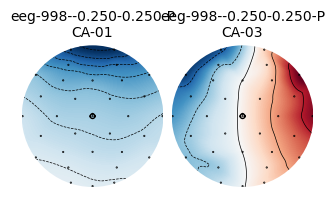

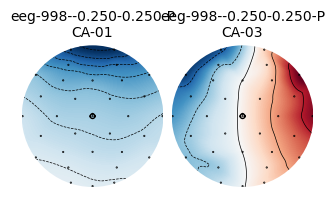

In [ ]:
raw.plot_projs_topomap()

In [ ]:
evoked_lead = lead.average()
evoked_lag = lag.average()

fname_left = fpath+resultsdir+subj + '_evoked_lead_ave2.fif'
fname_right = fpath+resultsdir+subj + '_evoked_lag_ave2.fif'

evoked_lead.save(fname_left,overwrite=True)
evoked_lag.save(fname_right, overwrite=True)

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_27409/3435254540.py:7: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP017_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead.save(fname_left,overwrite=True)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_27409/3435254540.py:8: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP017_evoked_lag_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lag.save(fname_right, overwrite=True)


In [ ]:
# del lead, lag, evoked_lag, evoked_lead, events_lag, events_lead, events_lag_use, events_lead_use
# gc.collect()

In [ ]:
evoked_left = left.average()
evoked_right = right.average()

In [ ]:
# fname_left = fpath+resultsdir+subj + '_evoked_left_ave.fif'
# fname_right = fpath+resultsdir+subj + '_evoked_right_ave.fif'

# evoked_left.save(fname_left,overwrite=True)
# evoked_right.save(fname_right, overwrite=True)

# evoked_left.filter(1, 20)
# evoked_right.filter(1, 20)

# x = evoked_left.data * 1e6
# t = evoked_right.times
# y = evoked_right.data * 1e6
# sum_x = np.zeros([evoked_left.data.shape[1]])
# sum_y = np.zeros([evoked_left.data.shape[1]])
# for i in [30,31,4,25]:
#     sum_x += x[i,]
#     sum_y += y[i,]
# z = np.asarray((sum_x/4, sum_y/4))
# pl.plot(t, z.T, linewidth=1)
# pl.xlabel('Time (s)', fontsize=12)
# pl.ylabel('Evoked Potential (µV)', fontsize=12)
# pl.legend(['Attend Left', 'Attend Right'], loc='best')
# pl.show()

Setting up band-pass filter from 1 - 20 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 20.00 Hz
- Upper transition bandwidth: 5.00 Hz (-6 dB cutoff frequency: 22.50 Hz)
- Filter length: 54069 samples (3.300 s)

Setting up band-pass filter from 1 - 20 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 20.00 Hz
- Upper transition bandwidth: 5.00 Hz (-6 dB cutoff frequency: 22.50 Hz)
- Fi

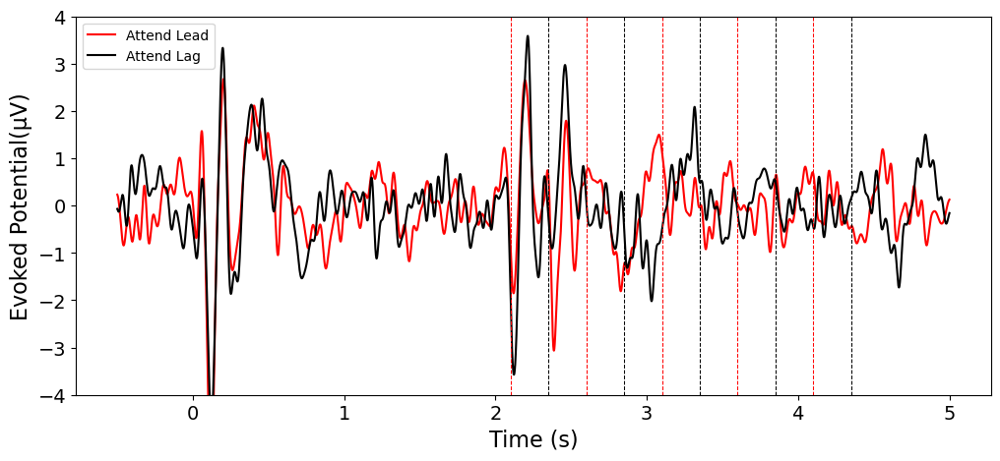

In [ ]:
# evoked_lead = lead.average()
# evoked_lag = lag.average()

evoked_lead.filter(1, 20)
evoked_lag.filter(1, 20)

x = evoked_lead.data * 1e6
t = evoked_lag.times
y = evoked_lag.data * 1e6
sum_x = np.zeros([evoked_lead.data.shape[1]])
sum_y = np.zeros([evoked_lead.data.shape[1]])
for i in [30,31,4,25]:
    sum_x += x[i,]
    sum_y += y[i,]
z = np.asarray((sum_x/4, sum_y/4))
time = np.linspace(-0.5, 5, y.shape[1])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(time, z[0], linewidth=1.5, color='red', label='Evoked Lead') 
ax.plot(time, z[1], linewidth=1.5, color='black', label='Evoked Lag')
# ax.axvline(x=0.4, linestyle='--', linewidth=0.75, color='blue')  
for x_val in [2.1, 2.6, 3.1, 3.6, 4.1]:
    ax.axvline(x=x_val, linestyle='--', linewidth=0.75, color='red')
for x_val in [2.35, 2.85, 3.35, 3.85, 4.35]:
    ax.axvline(x=x_val, linestyle='--', linewidth=0.75, color='black')
ax.set_xlabel('Time (s)', fontsize=16)
ax.set_ylabel('Evoked Potential(µV)', fontsize=16)
ax.set_ylim(-4,4)
ax.tick_params(axis='both', labelsize=14)
ax.legend(['Attend Lead', 'Attend Lag'], loc='upper left')
# plt.savefig(foldername+'Evoked_NH_newest.pdf', format='pdf')
plt.show()

In [ ]:
epoch_left_pre = left.copy().crop(tmin=0.4, tmax=1.6)
epoch_right_pre = right.copy().crop(tmin=0.4, tmax=1.6) 

In [ ]:
# epoch_left_dur = left.copy().crop(tmin=2.0, tmax=4.4)
# epoch_right_dur = right.copy().crop(tmin=2.0, tmax=4.4) 

In [ ]:
freqs = np.arange(6., 14., 1.)
n_cycles = freqs / 2.0

In [ ]:
del raw, eves, left, right
gc.collect()

4303

In [ ]:
# power_alpha_left_pre = epoch_left_pre.compute_tfr(method="multitaper", freqs=freqs, picks=['eeg'], return_itc=False, n_cycles=n_cycles)
# power_alpha_right_pre = epoch_right_pre.compute_tfr(method="multitaper", freqs=freqs, picks=['eeg'], return_itc=False, n_cycles=n_cycles)

# del epoch_right_pre

# fname_pleft_pre = fpath+resultsdir+subj+ '_left_alpha_preprestim_tfr.h5'     #'_left_alpha_preprestim_new_tfr.h5'
# fname_pright_pre = fpath+resultsdir+subj+ '_right_alpha_preprestim_tfr.h5'

# power_alpha_left_pre.save(fname_pleft_pre, overwrite=True)
# power_alpha_right_pre.save(fname_pright_pre, overwrite=True)

In [ ]:
# power_alpha_left_dur = epoch_left_dur.compute_tfr(method="multitaper", freqs=freqs, picks=['eeg'], return_itc=False, n_cycles=n_cycles)
# power_alpha_right_dur = epoch_right_dur.compute_tfr(method="multitaper", freqs=freqs, picks=['eeg'], return_itc=False, n_cycles=n_cycles)

# del epoch_right_dur

# # fname_pleft_dur = fpath+resultsdir+subj+ '_left_alpha_dur_new_tfr.h5'
# # fname_pright_dur = fpath+resultsdir+subj+ '_right_alpha_dur_new_tfr.h5'

# # power_alpha_left_dur.save(fname_pleft_dur, overwrite=True)
# # power_alpha_right_dur.save(fname_pright_dur, overwrite=True)

In [ ]:
avg_power_alpha_left_pre = power_alpha_left_pre.data.mean(axis=0).mean(axis=1).mean(axis=1)
avg_power_alpha_right_pre = power_alpha_right_pre.data.mean(axis=0).mean(axis=1).mean(axis=1)

norm_avg_power_alpha_right_left_pre = (avg_power_alpha_right_pre - avg_power_alpha_left_pre)/((avg_power_alpha_left_pre + avg_power_alpha_right_pre)*0.5)*100 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_22382/290420151.py:6: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  im,_ = mne.viz.plot_topomap(norm_avg_power_alpha_right_left_pre, info_picked, names=channels,  axes=ax, ch_type='eeg',show=False)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_22382/290420151.py:6: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  im,_ = mne.viz.plot_topomap(norm_avg_power_alpha_right_left_pre, info_picked, names=channels,  axes=ax, ch_type='eeg',show=False)


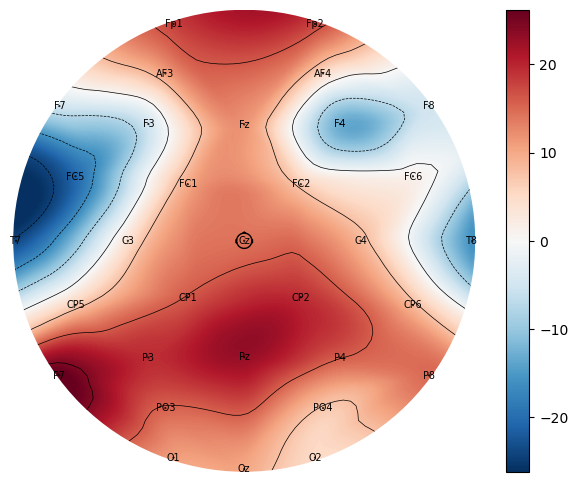

In [ ]:
channels = ['Fp1','AF3','F7','F3','FC1','FC5','T7','C3','CP1','CP5','P7','P3','Pz','PO3',
 'O1','Oz','O2','PO4','P4','P8','CP6','CP2','C4','T8','FC6','FC2','F4','F8','AF4','Fp2','Fz','Cz']
info_picked = mne.pick_info(epoch_left_pre.info, mne.pick_channels(epoch_left_pre.info['ch_names'], include =channels))

fig, ax = plt.subplots(figsize=(8, 6))
im,_ = mne.viz.plot_topomap(norm_avg_power_alpha_right_left_pre, info_picked, names=channels,  axes=ax, ch_type='eeg',show=False)
plt.colorbar(im, ax=ax)
plt.show()

In [ ]:
# averaged_epochright_pre = epoch_right_pre.average()
# averaged_epochleft_pre = epoch_left_pre.average()

In [ ]:
# power_right = averaged_epochright_pre.compute_tfr(method="multitaper", freqs=freqs, n_cycles=n_cycles, picks=[18,20,21,22,23]) 
# power_left = averaged_epochleft_pre.compute_tfr(method="multitaper", freqs=freqs, n_cycles=n_cycles, picks=[11,9,8,7,6])

In [ ]:
# power_left.plot(picks=[0], baseline=(0.4, 0.6), mode='zlogratio')

In [ ]:
# avg_power_alpha_left_dur = power_alpha_left_dur.data.mean(axis=0).mean(axis=1).mean(axis=1)
# avg_power_alpha_right_dur = power_alpha_right_dur.data.mean(axis=0).mean(axis=1).mean(axis=1)

# norm_avg_power_alpha_right_left_dur = (avg_power_alpha_right_dur - avg_power_alpha_left_dur)/(avg_power_alpha_left_dur + avg_power_alpha_right_dur)*0.5*100

In [ ]:
# channels = ['Fp1','AF3','F7','F3','FC1','FC5','T7','C3','CP1','CP5','P7','P3','Pz','PO3',
#  'O1','Oz','O2','PO4','P4','P8','CP6','CP2','C4','T8','FC6','FC2','F4','F8','AF4','Fp2','Fz','Cz']
# info_picked = mne.pick_info(epoch_left_dur.info, mne.pick_channels(epoch_left_dur.info['ch_names'], include =channels))

# fig, ax = plt.subplots(figsize=(8, 6))
# im,_ = mne.viz.plot_topomap(norm_avg_power_alpha_right_left_dur, info_picked, names=channels,  axes=ax, ch_type='eeg',show=False)
# plt.colorbar(im, ax=ax)
# plt.show()

In [ ]:
fname_left_right_pre = fpath+resultsdir+subj+ '_norm_right_left_preprestim' #'_norm_right_left_preprestim'
print(fname_left_right_pre)
np.save(fname_left_right_pre, norm_avg_power_alpha_right_left_pre)

# fname_left_right_dur = fpath+resultsdir+subj+ '_norm_right_left_dur'
# np.save(fname_left_right_dur, norm_avg_power_alpha_right_left_dur)

del avg_power_alpha_left_pre, avg_power_alpha_right_pre, norm_avg_power_alpha_right_left_pre, 
# del avg_power_alpha_left_dur,avg_power_alpha_right_dur, norm_avg_power_alpha_right_left_dur
gc.collect()

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL002_norm_right_left_preprestim


/opt/anaconda3/envs/EEG/lib/python3.12/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/opt/anaconda3/envs/EEG/lib/python3.12/ast.py:587: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)


NameError: name 'norm_avg_power_alpha_right_left_pre' is not defined

## All subjects save Evoked and Alpha figures saving

In [ ]:
import mne
from anlffr.helper import biosemi2mne as bs
from anlffr.preproc import find_blinks
from matplotlib import pyplot as plt
from mne import compute_proj_epochs
from mne import concatenate_epochs
import pylab as pl
import numpy as np
import os
import fnmatch
from scipy.fft import fft
from scipy.signal import find_peaks
import gc 

['HL002', 'HL004']
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/
HL002
['HL002_AttentionTask+001.bdf', 'HL002_AttentionTask+003.bdf', 'HL002_AttentionTask+002.bdf', 'HL002_AttentionTask+004.bdf', 'HL002_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL002_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
119 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Run

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4680/3645869076.py:198: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap()
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4680/3645869076.py:198: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap()
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4680/3645869076.py:198: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap()
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4680/3645869076.py:198: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap()
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4680/3645869076.py:198: RuntimeWarning: Only 6 head digitization points of the specified ki

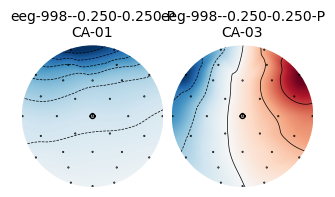

Overwriting existing file.
Overwriting existing file.
Overwriting existing file.
Overwriting existing file.
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Overwriting existing file.
Overwriting existing file.


/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4680/3645869076.py:281: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  mne.viz.plot_topomap(
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4680/3645869076.py:281: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  mne.viz.plot_topomap(


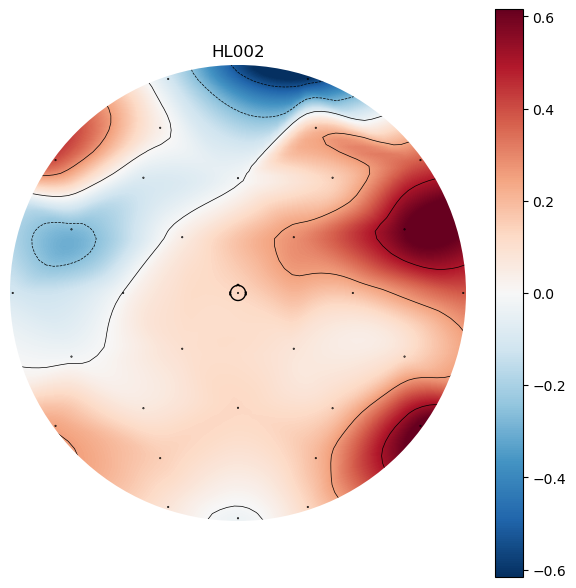

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/resultsMar2026/HL002_norm_right_left_preprestim
HL004
['HL004_AttentionTask+004.bdf', 'HL004_AttentionTask+002.bdf', 'HL004_AttentionTask+003.bdf', 'HL004_AttentionTask+001.bdf', 'HL004_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL004_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1949695  =      0.000 ...   119.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
20 events found on stim channel Status
Event IDs:

/opt/anaconda3/envs/EEG/lib/python3.12/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/opt/anaconda3/envs/EEG/lib/python3.12/ast.py:587: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)


KeyboardInterrupt: 

In [ ]:
resultsdir = 'resultsMar2026/'
foldername = '/Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/Figures/evoked_alpha'

HL_subjects = ['HL002', 'HL004']
NH_subjects = []

left_elecs  = ['Fp1', 'AF3', 'F7', 'F3', 'FC1', 'FC5', 'T7', 'C3', 'CP1', 'CP5', 'P7', 'P3', 'PO3', 'O1']
right_elecs = ['Fp2', 'AF4', 'F8', 'F4', 'FC2', 'FC6', 'T8', 'C4', 'CP2', 'CP6', 'P8', 'P4', 'PO4', 'O2']

freqs    = np.arange(6., 14., 1.)
n_cycles = freqs / 2.0

subjects = HL_subjects + NH_subjects

# subjects = ['HR']

print(subjects)

fpath = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/'

print(fpath)

for subj in subjects:
    print(subj)
    leads = []
    lags = []
    lefts = []
    rights = []

    event_counts = {2: 0, 3: 0, 4: 0, 5: 0, 6: 0}
    channels_to_drop = ['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']
    
    bdfs = fnmatch.filter(os.listdir(fpath), subj + '_Att*.bdf')
    bdfs = fnmatch.filter(os.listdir(fpath), subj + '_Att*.bdf')
    if subj == 'HL012':
        bdfs = ['HL012_AttentionTask.bdf', 'HL012_AttentionTask+004.bdf', 'HL012_AttentionTask+005.bdf', 'HL012_AttentionTask+006.bdf', 'HL012_AttentionTask+002.bdf', 'HL012_AttentionTask+003.bdf', 'HL012_AttentionTask+001.bdf']
    if subj == 'HL025':
        bdfs = ['HL025_AttentionTask+002.bdf', 'HL025_AttentionTask+003.bdf', 'HL025_AttentionTask+004.bdf']
    if subj == 'HL036':
        bdfs = ['HL036_AttentionTask+001.bdf', 'HL036_AttentionTask+002.bdf', 'HL036_AttentionTask+003.bdf', 'HL036_AttentionTask+004.bdf']
    if subj == 'SP014':
        bdfs = ['SP014_AttentionTask.bdf', 'SP014_AttentionTask+004.bdf', 'SP014_AttentionTask+002.bdf', 'SP014_AttentionTask+003.bdf', 'SP014_AttentionTask+001.bdf']
    if subj == 'HL008':
        bdfs = ['HL008_AttentionTask+004.bdf', 'HL008_AttentionTask+003.bdf', 'HL008_AttentionTask+002.bdf', 'HL008_AttentionTask+001.bdf', 'HL008_AttentionTask.bdf']
        ###ABR has been recorded with the same name as Attention - check to make sure it's written somewhere 
    print(bdfs)
    
    for k, bdf in enumerate(bdfs):
        if bdf == 'HL008_AttentionTask+004.bdf':
            bdf_fullpath = os.path.join(fpath, bdf)
            raw, eves = bs.importbdf(bdf_fullpath, hptsname='biosemi10_20.hpts')
            total = raw.times[-1]
            end_time = total - 120
            raw = raw.crop(tmin=0, tmax=end_time)
        else:
            bdf_fullpath = os.path.join(fpath, bdf)
            raw, eves = bs.importbdf(bdf_fullpath, hptsname='biosemi10_20.hpts') 
        print(f'Running file: {bdf}')
        raw.notch_filter(
            np.arange(60, 241, 60),
            filter_length='auto',
            fir_design='firwin',
            method='fir'
        )
        raw.filter(1., 40., fir_design='firwin')

        if subj == 'SP004' or subj == 'SP019':
            raw.drop_channels(channels_to_drop)

        blinks = find_blinks(raw, ch_name=['Fp1'])

        if subj in ['HL047']:
            if k ==0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=1)
            raw.add_proj(blink_proj)
            raw.apply_proj()

        elif subj in ['HR', 'SP004', 'HL004', 'HL007', 'HL010', 'HL022', 'HL031']:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=2)
            
            raw.add_proj(blink_proj)
            #raw.del_proj(1)
            raw.apply_proj()
        
        elif subj == 'HL022':
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=4)
            
            raw.add_proj(blink_proj)
            raw.del_proj(1)
            raw.del_proj(2)
            raw.apply_proj()

        else:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=3)
            
            raw.add_proj(blink_proj)
            raw.del_proj(1)
            raw.apply_proj()

        # print(eves)
            
        for event_id in [2, 3, 4, 5, 6]:
            event_counts[event_id] += np.sum(eves[:, 2] == event_id)
    
        events_left = [7,8]
        # events_left_use = [event_left for event_left in events_left if event_left in eves[:,2]]
        
        events_right = [9,10]
        # events_right_use = [event_right for event_right in events_right if event_right in eves[:,2]]

        events_lead = [7,9]
        # events_lead_use = [event_lead for event_lead in events_lead if event_lead in eves[:,2]]

        events_lag = [8,10]
        # events_lag_use = [event_lag for event_lag in events_lag if event_lag in eves[:,2]]

        cue_ids = np.array([7, 8, 9, 10])
        resp_ids = np.array([1, 2, 3, 4, 5, 6])

        # indices of cue events in eves
        cue_idx = np.where(np.isin(eves[:, 2], cue_ids))[0]

        keep_cue_idx = []
        for i in cue_idx:
            # look forward in the event list
            after = eves[i+1:]
            # first "response-type" event after this cue (ignore other codes like 11, etc.)
            resp_pos = np.where(np.isin(after[:, 2], resp_ids))[0]
            if len(resp_pos) == 0:
                continue  # no response found for this cue
            first_resp_code = after[resp_pos[0], 2]
            if first_resp_code in [1,2,3,4,5]:
                keep_cue_idx.append(i)

        # filtered events array: keep only cues with response==5 (plus all non-cue events if you want)
        eves_cue_resp5 = eves[keep_cue_idx]

        events_left  = [7, 8]
        events_right = [9, 10]
        events_lead  = [7, 9]
        events_lag   = [8, 10]

        def events_present(events, eves):
            return [e for e in events if e in eves[:, 2]]

        events_left_use  = events_present(events_left,  eves_cue_resp5)
        events_right_use = events_present(events_right, eves_cue_resp5)
        events_lead_use  = events_present(events_lead,  eves_cue_resp5)
        events_lag_use   = events_present(events_lag,   eves_cue_resp5)
            
        if events_left_use:
            epochs_left = mne.Epochs(raw, eves_cue_resp5, event_id=events_left_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_right_use:
            epochs_right = mne.Epochs(raw, eves_cue_resp5, event_id=events_right_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_lead_use:
            epochs_lead = mne.Epochs(raw, eves_cue_resp5, event_id=events_lead_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_lag_use:
            epochs_lag = mne.Epochs(raw, eves_cue_resp5, event_id=events_lag_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
            
        if events_left_use:
            lefts.append(epochs_left)

        if events_right_use:
            rights.append(epochs_right)

        if events_lead_use:
            leads.append(epochs_lead)

        if events_lag_use:
            lags.append(epochs_lag)

    left  = mne.concatenate_epochs(lefts,  on_mismatch="ignore") if lefts  else None
    right = mne.concatenate_epochs(rights, on_mismatch="ignore") if rights else None
    lead  = mne.concatenate_epochs(leads,  on_mismatch="ignore") if leads  else None
    lag   = mne.concatenate_epochs(lags,   on_mismatch="ignore") if lags   else None

    for event_id, count in event_counts.items():
        print(f"{event_id}: {count} ")

    evoked_lead = lead.average()
    evoked_lag = lag.average()

    raw.plot_projs_topomap()

    fname_left = fpath+resultsdir+subj + '_evoked_lead_resp_ave.fif'
    fname_right = fpath+resultsdir+subj + '_evoked_lag_resp_ave.fif'

    evoked_lead.save(fname_left,overwrite=True)
    evoked_lag.save(fname_right, overwrite=True)

    # evoked_lead.filter(1, 20)
    # evoked_lag.filter(1, 20)

    # x = evoked_lead.data * 1e6
    # t = evoked_lag.times
    # y = evoked_lag.data * 1e6
    # sum_x = np.zeros([evoked_lead.data.shape[1]])
    # sum_y = np.zeros([evoked_lead.data.shape[1]])
    # for i in [30,31,4,25]:
    #     sum_x += x[i,]
    #     sum_y += y[i,]
    # z = np.asarray((sum_x/4, sum_y/4))
    # # time = np.linspace(-0.5, 5, y.shape[1])

    # fig, ax = plt.subplots(figsize=(12, 5))
    # ax.plot(t, z[0], linewidth=1.5, color='red', label='Evoked Lead') 
    # ax.plot(t, z[1], linewidth=1.5, color='black', label='Evoked Lag')
    # # ax.axvline(x=0.4, linestyle='--', linewidth=0.75, color='blue')  
    # for x_val in [2.1, 2.6, 3.1, 3.6, 4.1]:
    #     ax.axvline(x=x_val, linestyle='--', linewidth=0.75, color='red')
    # for x_val in [2.35, 2.85, 3.35, 3.85, 4.35]:
    #     ax.axvline(x=x_val, linestyle='--', linewidth=0.75, color='black')
    # ax.set_xlabel('Time (s)', fontsize=16)
    # ax.set_ylabel('Evoked Potential(µV)', fontsize=16)
    # ax.set_ylim(-4,4)
    # ax.tick_params(axis='both', labelsize=14)
    # ax.legend(['Attend Lead', 'Attend Lag'], loc='upper left')
    # plt.savefig(os.path.join(foldername, f"{subj}_Evoked_resp5.jpg"), format="jpg")
    # plt.show()
    
    del lead, lag, evoked_lead, evoked_lag
    gc.collect()

    left = left.crop(tmin=-0.5,  tmax=1.6)
    right = right.crop(tmin=-0.5,  tmax=1.6)

    epoch_left = left.average()
    epoch_right = right.average()

    power_left = left.compute_tfr(method="multitaper",freqs=freqs,n_cycles=n_cycles,picks='eeg',return_itc=False,average=True)

    power_right = right.compute_tfr(method="multitaper",freqs=freqs,n_cycles=n_cycles,picks='eeg',return_itc=False,average=True)

    # power_left.apply_baseline(baseline=(-0.5, 0.0),  mode='ratio')
    # power_right.apply_baseline(baseline=(-0.5, 0.0), mode='ratio')

    power_left.crop(tmin=0.4,  tmax=1.6)
    power_right.crop(tmin=0.4, tmax=1.6)

    fname_pleft_pre = fpath+resultsdir+subj+ '_left_alpha_preprestim_tfr.h5'     #'_left_alpha_preprestim_new_tfr.h5'
    fname_pright_pre = fpath+resultsdir+subj+ '_right_alpha_preprestim_tfr.h5'

    power_left.save(fname_pleft_pre, overwrite=True)
    power_right.save(fname_pright_pre, overwrite=True)

    alpha_idx = np.where((freqs >= 6) & (freqs <= 14))[0]

    power_attend_left  = power_left.data[:,  :, alpha_idx, :].mean(axis=(0, 2, 3))
    power_attend_right = power_right.data[:, :, alpha_idx, :].mean(axis=(0, 2, 3))

    topo_data = ((power_attend_right - power_attend_left) / ((power_attend_right + power_attend_left) / 2)) * 100

    fig, ax = plt.subplots(figsize=(6, 6))

    mne.viz.plot_topomap(
        topo_data,
        power_left.info,
        axes=ax,
        cmap='RdBu_r',
        vlim=(-np.max(np.abs(topo_data)), np.max(np.abs(topo_data))),
        show=False
    )

    ax.set_title(f'{subj}')
    plt.colorbar(ax.images[0], ax=ax)
    plt.tight_layout()
    # plt.savefig('alpha_contrast_topomap.png', dpi=300)
    plt.show()

    fname_left_right_pre = fpath+resultsdir+subj+ '_norm_right_left_preprestim' #'_norm_right_left_preprestim'
    print(fname_left_right_pre)
    np.save(fname_left_right_pre, topo_data)

    del left, right, power_left, power_right, topo_data
    gc.collect() 


## Let's try this again

['HL002', 'HL004', 'HL005', 'HL007', 'HL008', 'HL011', 'HL018', 'HL023', 'HL025', 'HL031', 'HL040', 'HL045', 'HL046', 'HL048', 'HL049', 'HL047', 'HL050', 'SP003', 'SP004', 'SP005', 'SP006', 'SP007', 'SP008', 'SP010', 'SP012', 'SP013', 'SP014', 'SP016', 'SP019', 'SP017', 'HL017', 'HL029', 'HL036', 'HR']
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/
HL002
['HL002_AttentionTask+001.bdf', 'HL002_AttentionTask+003.bdf', 'HL002_AttentionTask+002.bdf', 'HL002_AttentionTask+004.bdf', 'HL002_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL002_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type se

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


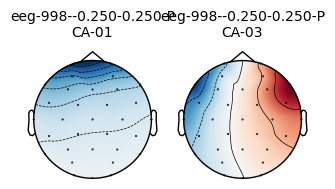

Approximating Fpz location by mirroring Oz along the X and Y axes.


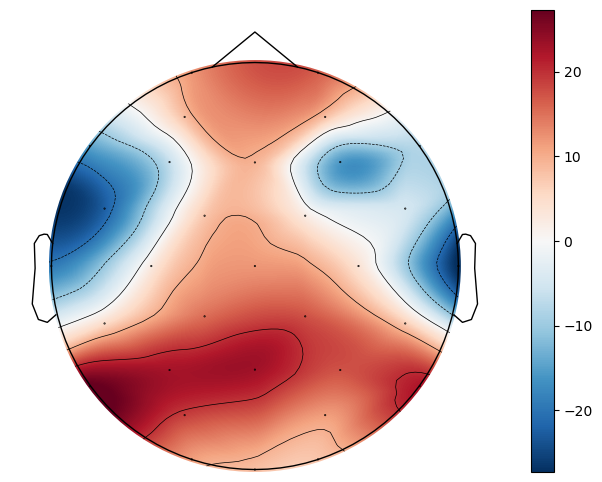

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL002_norm_right_left_preprestim
HL004
['HL004_AttentionTask+004.bdf', 'HL004_AttentionTask+002.bdf', 'HL004_AttentionTask+003.bdf', 'HL004_AttentionTask+001.bdf', 'HL004_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL004_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1949695  =      0.000 ...   119.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
20 events found on stim channel Status
Event IDs: [ 5  7

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


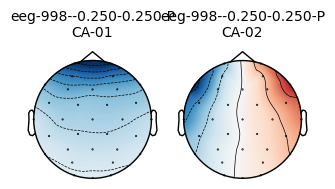

Approximating Fpz location by mirroring Oz along the X and Y axes.


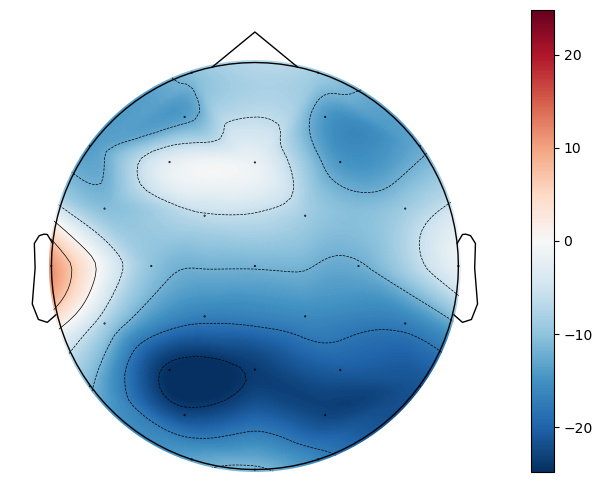

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL004_norm_right_left_preprestim
HL005
['HL005_AttentionTask+004.bdf', 'HL005_AttentionTask+005.bdf', 'HL005_AttentionTask+001.bdf', 'HL005_AttentionTask+002.bdf', 'HL005_AttentionTask+003.bdf', 'HL005_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL005_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
91 events found on stim c

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


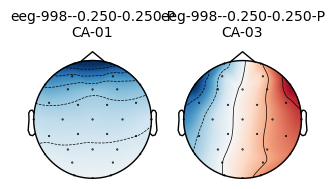

Approximating Fpz location by mirroring Oz along the X and Y axes.


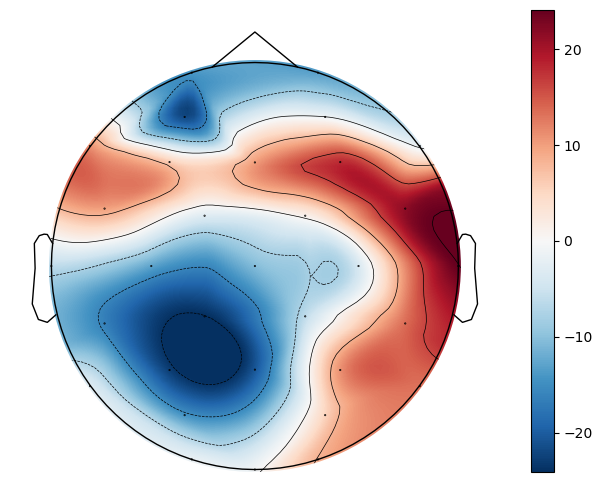

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL005_norm_right_left_preprestim
HL007
['HL007_AttentionTask+001.bdf', 'HL007_AttentionTask.bdf', 'HL007_AttentionTask+003.bdf', 'HL007_AttentionTask+002.bdf', 'HL007_AttentionTask+005.bdf', 'HL007_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL007_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
96 events found on stim c

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


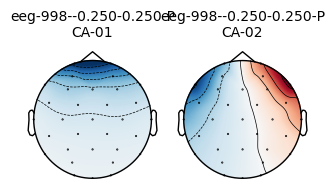

Approximating Fpz location by mirroring Oz along the X and Y axes.


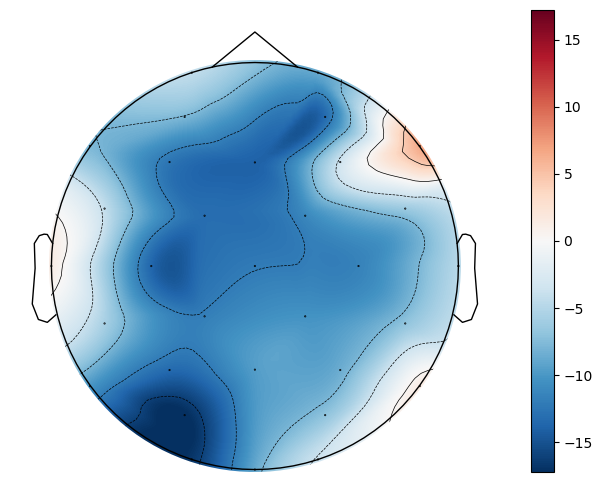

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL007_norm_right_left_preprestim
HL008
['HL008_AttentionTask+004.bdf', 'HL008_AttentionTask+003.bdf', 'HL008_AttentionTask+002.bdf', 'HL008_AttentionTask+001.bdf', 'HL008_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL008_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
82 events found on stim channel Status
Event IDs: [ 3  4

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


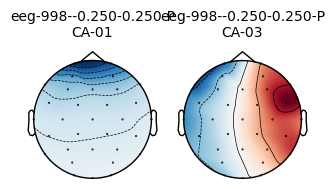

Approximating Fpz location by mirroring Oz along the X and Y axes.


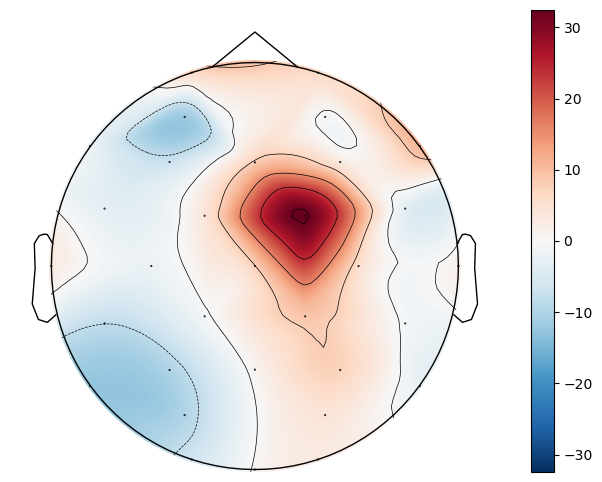

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL008_norm_right_left_preprestim
HL011
['HL011_AttentionTask.bdf', 'HL011_AttentionTask+001.bdf', 'HL011_AttentionTask+003.bdf', 'HL011_AttentionTask+002.bdf', 'HL011_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL011_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
96 events found on stim channel Status
Event IDs: [  4   5 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


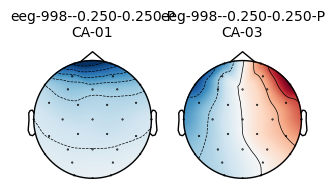

Approximating Fpz location by mirroring Oz along the X and Y axes.


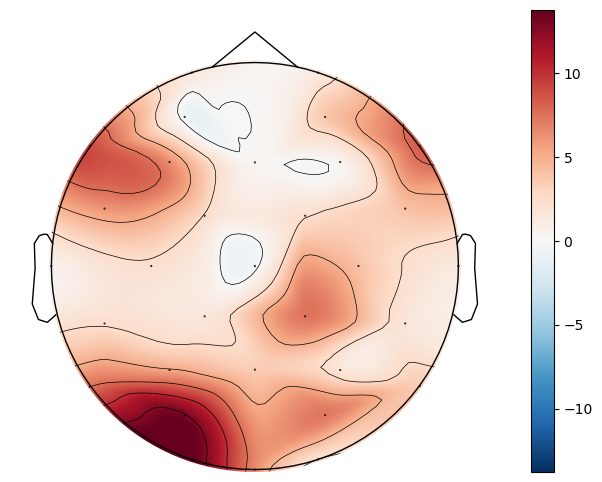

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL011_norm_right_left_preprestim
HL018
['HL018_AttentionTask+001.bdf', 'HL018_AttentionTask+003.bdf', 'HL018_AttentionTask+002.bdf', 'HL018_AttentionTask+004.bdf', 'HL018_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL018_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
114 events found on stim channel Status
Event IDs: [ 4  

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/preproc.py:58: RuntimeWarning: filter_length (360449) is longer than the signal (294912), distortion is likely. Reduce filter length or filter a longer signal.
  filteog = filter_data(eog, sampling_rate, l_freq, h_freq,


3 projection items deactivated
Created an SSP operator (subspace dimension = 2)
2 projection items activated
SSP projectors applied...
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL018_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
107 events found on stim channel Status
Event IDs: [  5   7   8   9  10  11 253]
Running file: HL018_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


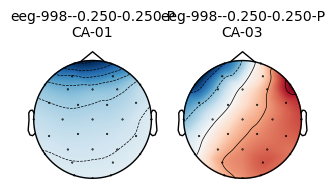

Approximating Fpz location by mirroring Oz along the X and Y axes.


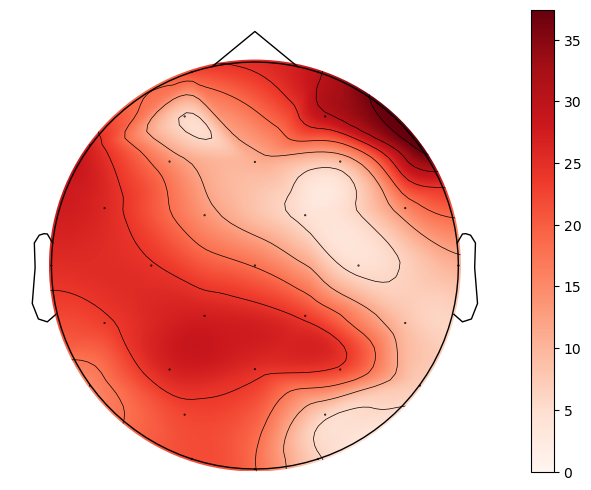

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL018_norm_right_left_preprestim
HL023
['HL023_AttentionTask.bdf', 'HL023_AttentionTask+002.bdf', 'HL023_AttentionTask+003.bdf', 'HL023_AttentionTask+001.bdf', 'HL023_AttentionTask+004.bdf', 'HL023_AttentionTask+005.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL023_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
72 events found on stim chan

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


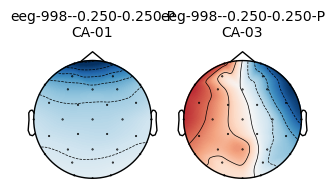

Approximating Fpz location by mirroring Oz along the X and Y axes.


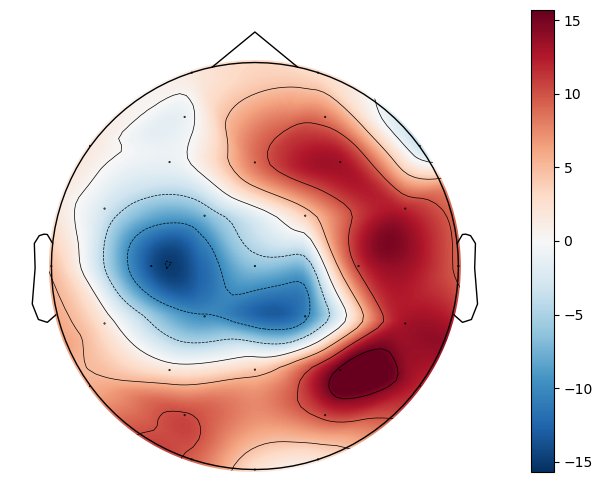

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL023_norm_right_left_preprestim
HL025
['HL025_AttentionTask+002.bdf', 'HL025_AttentionTask+003.bdf', 'HL025_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL025_AttentionTask+002.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
100 events found on stim channel Status
Event IDs: [ 2  3  4  5  7  8  9 10 11]
Running file: HL025_AttentionTask+

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


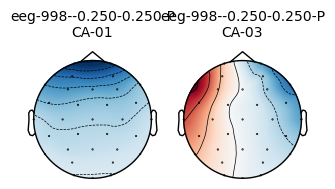

Approximating Fpz location by mirroring Oz along the X and Y axes.


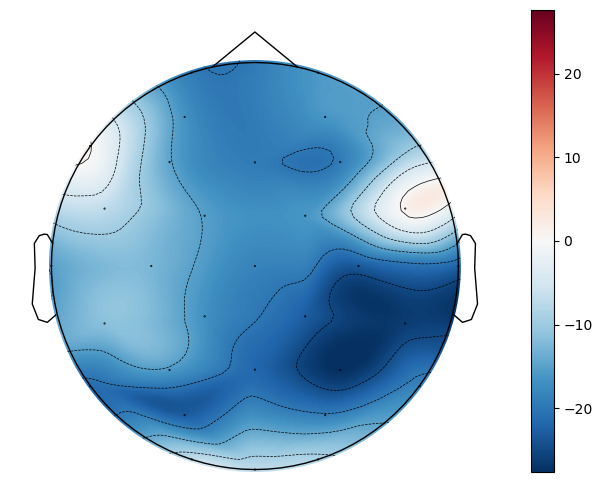

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL025_norm_right_left_preprestim
HL031
['HL031_AttentionTask+001.bdf', 'HL031_AttentionTask+002.bdf', 'HL031_AttentionTask.bdf', 'HL031_AttentionTask+003.bdf', 'HL031_AttentionTask+004.bdf', 'HL031_AttentionTask+005.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL031_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
101 events found on stim 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


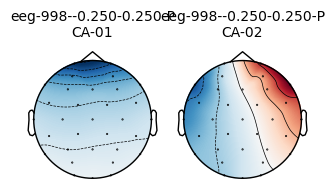

Approximating Fpz location by mirroring Oz along the X and Y axes.


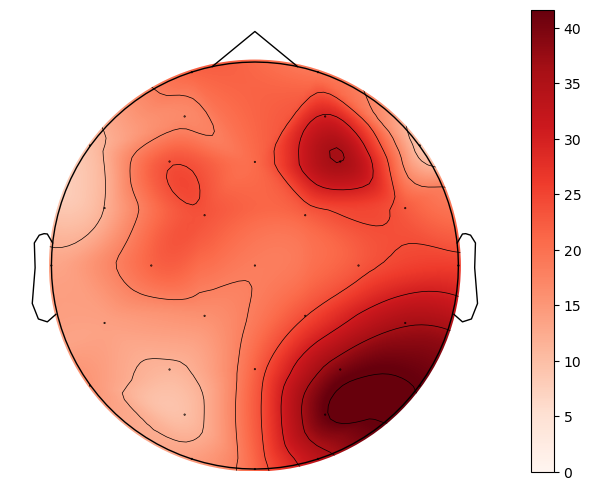

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL031_norm_right_left_preprestim
HL040
['HL040_AttentionTask+001.bdf', 'HL040_AttentionTask+002.bdf', 'HL040_AttentionTask+003.bdf', 'HL040_AttentionTask.bdf', 'HL040_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL040_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
95 events found on stim channel Status
Event IDs: [ 4  5

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


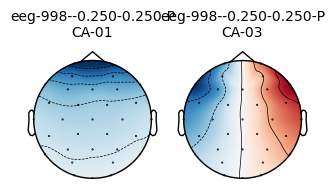

Approximating Fpz location by mirroring Oz along the X and Y axes.


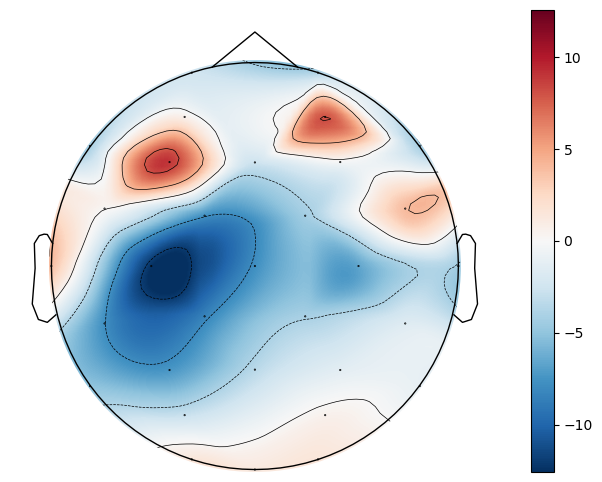

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL040_norm_right_left_preprestim
HL045
['HL045_AttentionTask.bdf', 'HL045_AttentionTask+001.bdf', 'HL045_AttentionTask+002.bdf', 'HL045_AttentionTask+003.bdf', 'HL045_AttentionTask+004.bdf', 'HL045_AttentionTask+005.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL045_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
76 events found on stim chan

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


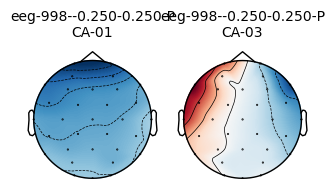

Approximating Fpz location by mirroring Oz along the X and Y axes.


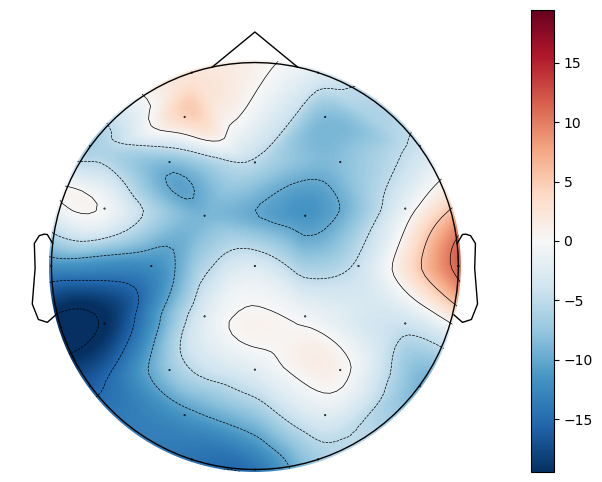

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL045_norm_right_left_preprestim
HL046
['HL046_AttentionTask+005.bdf', 'HL046_AttentionTask+004.bdf', 'HL046_AttentionTask+006.bdf', 'HL046_AttentionTask.bdf', 'HL046_AttentionTask+003.bdf', 'HL046_AttentionTask+002.bdf', 'HL046_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL046_AttentionTask+005.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this e

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


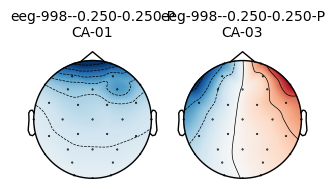

Approximating Fpz location by mirroring Oz along the X and Y axes.


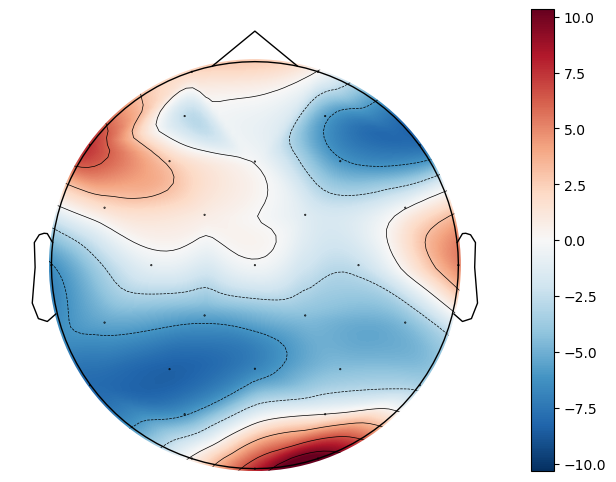

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL046_norm_right_left_preprestim
HL048
['HL048_AttentionTask+002.bdf', 'HL048_AttentionTask+003.bdf', 'HL048_AttentionTask+001.bdf', 'HL048_AttentionTask+004.bdf', 'HL048_AttentionTask+005.bdf', 'HL048_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL048_AttentionTask+002.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
90 events found on stim c

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


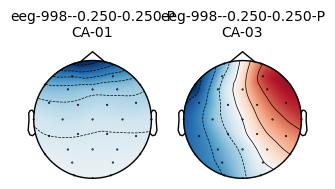

Approximating Fpz location by mirroring Oz along the X and Y axes.


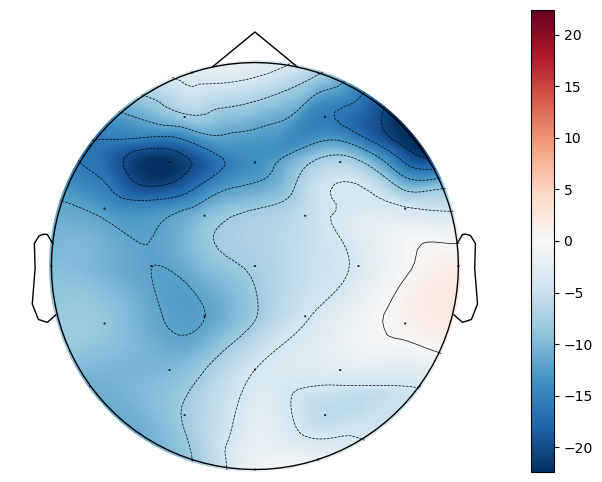

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL048_norm_right_left_preprestim
HL049
['HL049_AttentionTask.bdf', 'HL049_AttentionTask+001.bdf', 'HL049_AttentionTask+002.bdf', 'HL049_AttentionTask+003.bdf', 'HL049_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL049_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
89 events found on stim channel Status
Event IDs: [  4   5 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


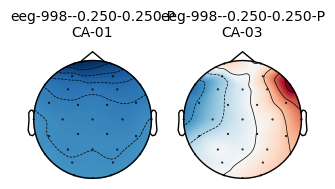

Approximating Fpz location by mirroring Oz along the X and Y axes.


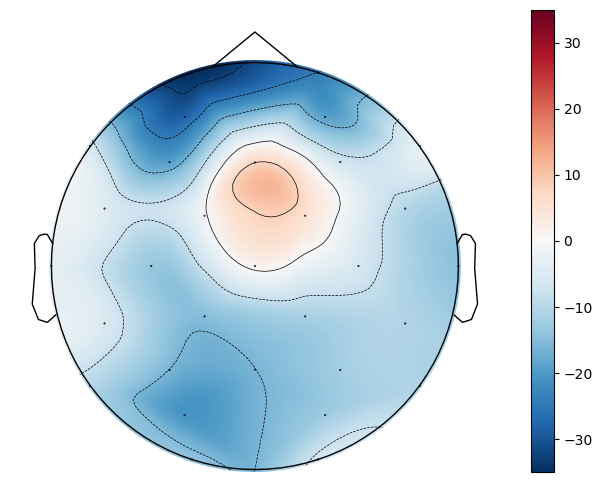

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL049_norm_right_left_preprestim
HL047
['HL047_Attention.bdf', 'HL047_Attention+001.bdf', 'HL047_Attention+002.bdf', 'HL047_Attention+003.bdf', 'HL047_Attention+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL047_Attention.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
74 events found on stim channel Status
Event IDs: [  1   3   4   5   7   8   9  10 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


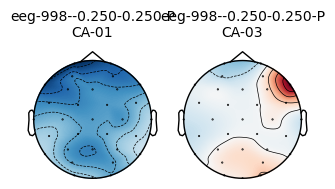

Approximating Fpz location by mirroring Oz along the X and Y axes.


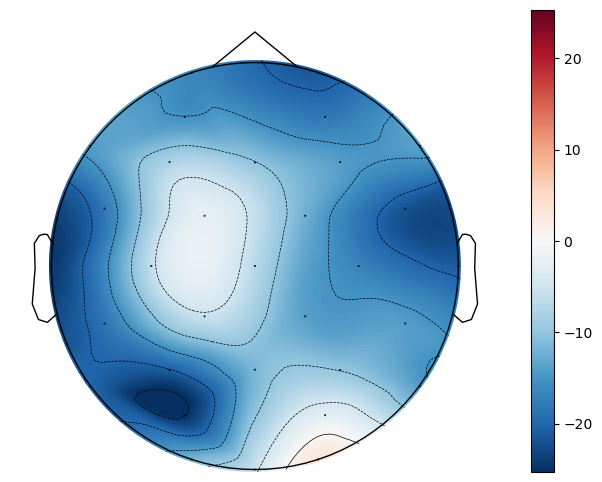

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL047_norm_right_left_preprestim
HL050
['HL050_AttentionTask+004.bdf', 'HL050_AttentionTask+003.bdf', 'HL050_AttentionTask+002.bdf', 'HL050_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL050_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
106 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Runnin

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


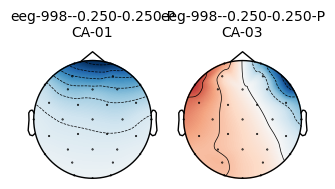

Approximating Fpz location by mirroring Oz along the X and Y axes.


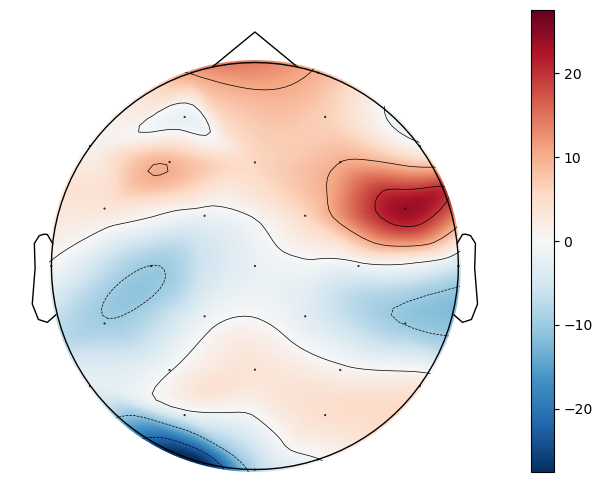

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL050_norm_right_left_preprestim
SP003
['SP003_Attention_Task+001.bdf', 'SP003_Attention_Task+002.bdf', 'SP003_Attention_Task+003.bdf', 'SP003_Attention_Task+004.bdf', 'SP003_Attention_Task+005.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP003_Attention_Task+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65535 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of t

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


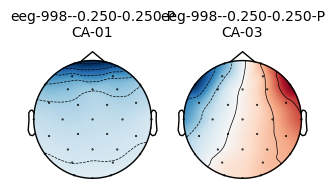

Approximating Fpz location by mirroring Oz along the X and Y axes.


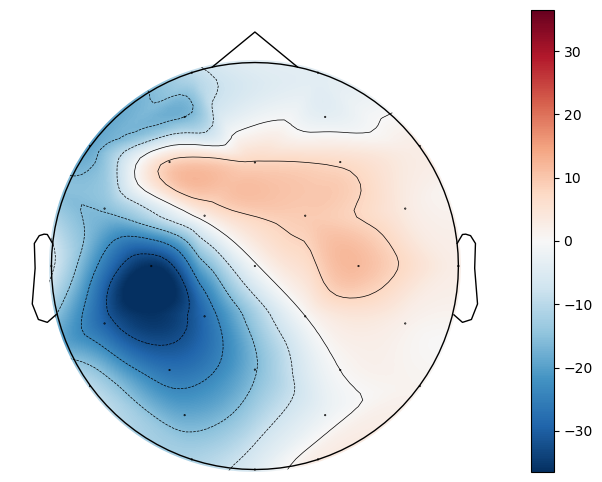

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP003_norm_right_left_preprestim
SP004
['SP004_AttentionTaskEEG.bdf', 'SP004_AttentionTaskEEG+004.bdf', 'SP004_AttentionTaskEEG+001.bdf', 'SP004_AttentionTaskEEG+003.bdf', 'SP004_AttentionTaskEEG+002.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP004_AttentionTaskEEG.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 7454719  =      0.000 ...   455.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.


/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
95 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP004_AttentionTaskEEG.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Running file: SP004_AttentionTaskEEG+004.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length

...

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
104 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP004_AttentionTaskEEG+003.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- L

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
102 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP004_AttentionTaskEEG+002.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- L

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


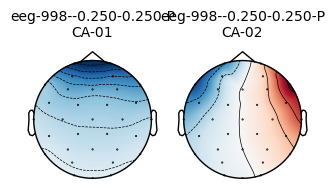

Approximating Fpz location by mirroring Oz along the X and Y axes.


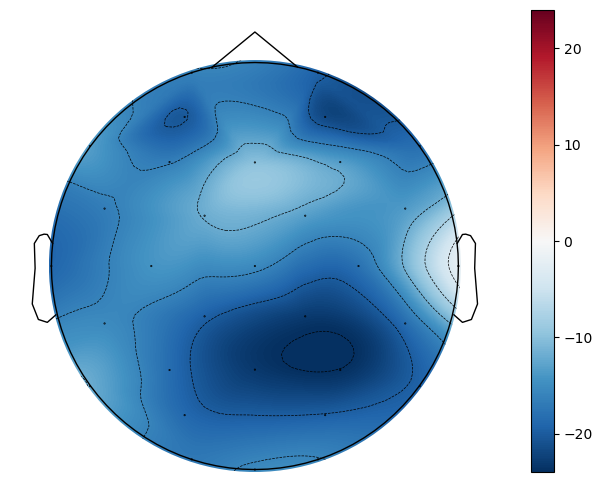

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP004_norm_right_left_preprestim
SP005
['SP005_AttentionTaskEEG.bdf', 'SP005_AttentionTaskEEG+001.bdf', 'SP005_AttentionTaskEEG+002.bdf', 'SP005_AttentionTaskEEG+003.bdf', 'SP005_AttentionTaskEEG+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP005_AttentionTaskEEG.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
101 events found on stim channel Status
E

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


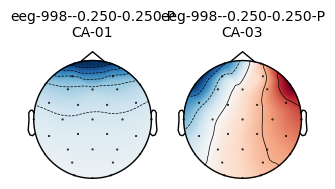

Approximating Fpz location by mirroring Oz along the X and Y axes.


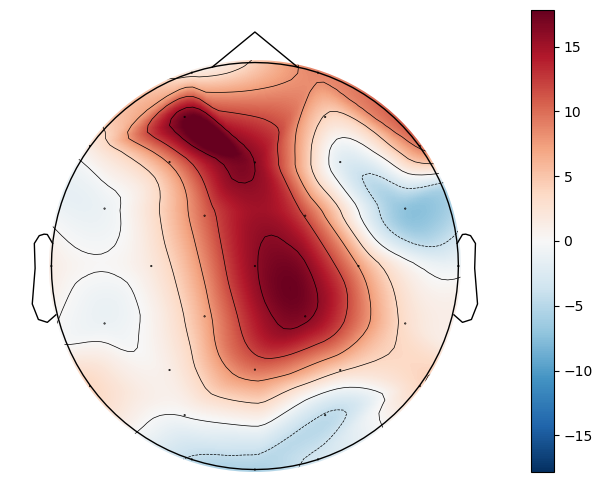

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP005_norm_right_left_preprestim
SP006
['SP006_Attentiontask.bdf', 'SP006_Attentiontask+002.bdf', 'SP006_Attentiontask+003.bdf', 'SP006_Attentiontask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP006_Attentiontask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
111 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file:

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


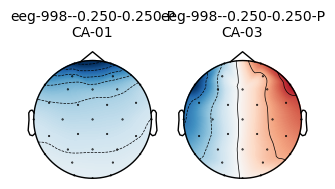

Approximating Fpz location by mirroring Oz along the X and Y axes.


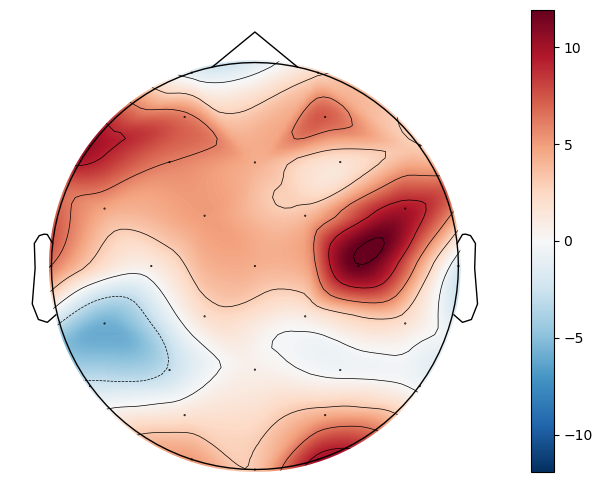

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP006_norm_right_left_preprestim
SP007
['SP007_Attentiontask.bdf', 'SP007_Attentiontask+004.bdf', 'SP007_Attentiontask+001.bdf', 'SP007_Attentiontask+002.bdf', 'SP007_Attentiontask+003.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP007_Attentiontask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
94 events found on stim channel Status
Event IDs: [ 4  5  7

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:190: RuntimeWarning: All epochs were dropped!
You might need to alter reject/flat-criteria or drop bad channels to avoid this. You can use Epochs.plot_drop_log() to see which channels are responsible for the dropping of epochs.
  lag   = mne.concatenate_epochs(lags,   on_mismatch="ignore") if lags   else None
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:190: RuntimeWarning: One of the Epochs objects to concatenate was empty.
  lag   = mne.concatenate_epochs(lags,   on_mismatch="ignore") if lags   else None


2 bad epochs dropped
Using data from preloaded Raw for 17 events and 90113 original time points ...
    Rejecting  epoch based on EEG : ['FC5', 'T7', 'CP5', 'CP6', 'T8', 'FC6']
    Rejecting  epoch based on EEG : ['T7']
2 bad epochs dropped
Using data from preloaded Raw for 16 events and 90113 original time points ...
    Rejecting  epoch based on EEG : ['CP5']
    Rejecting  epoch based on EEG : ['FC5']
    Rejecting  epoch based on EEG : ['FC5', 'CP5']
3 bad epochs dropped
Using data from preloaded Raw for 13 events and 90113 original time points ...
Using data from preloaded Raw for 0 events and 90113 original time points ...
Using data from preloaded Raw for 17 events and 90113 original time points ...


/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:190: RuntimeWarning: epochs._get_data() can't run because this Epochs-object is empty. You might want to check Epochs.drop_log or Epochs.plot_drop_log() to see why epochs were dropped.
  lag   = mne.concatenate_epochs(lags,   on_mismatch="ignore") if lags   else None


Using data from preloaded Raw for 15 events and 90113 original time points ...
Using data from preloaded Raw for 13 events and 90113 original time points ...
Not setting metadata
58 matching events found
Applying baseline correction (mode: mean)
Created an SSP operator (subspace dimension = 2)
2: 4 
3: 14 
4: 34 
5: 96 
6: 1 
Approximating Fpz location by mirroring Oz along the X and Y axes.


/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


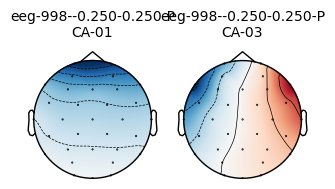

Approximating Fpz location by mirroring Oz along the X and Y axes.


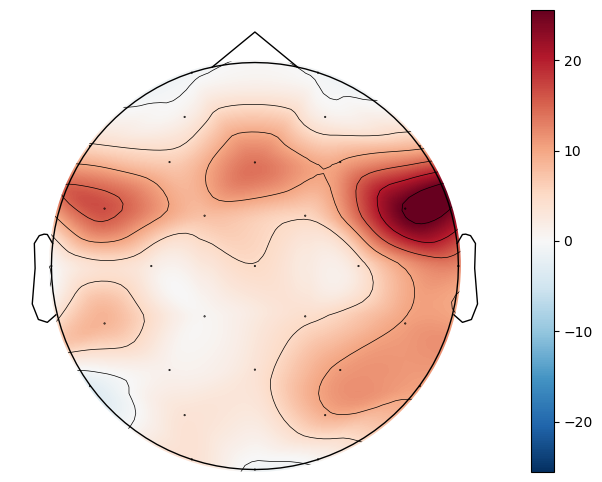

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP007_norm_right_left_preprestim
SP008
['SP008_AttentionTask+003.bdf', 'SP008_AttentionTask+002.bdf', 'SP008_AttentionTask+001.bdf', 'SP008_AttentionTask+004.bdf', 'SP008_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP008_AttentionTask+003.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
109 events found on stim channel Status
Event IDs: [ 3  

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


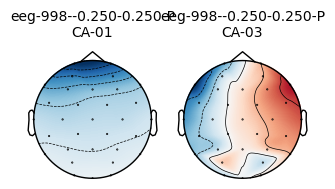

Approximating Fpz location by mirroring Oz along the X and Y axes.


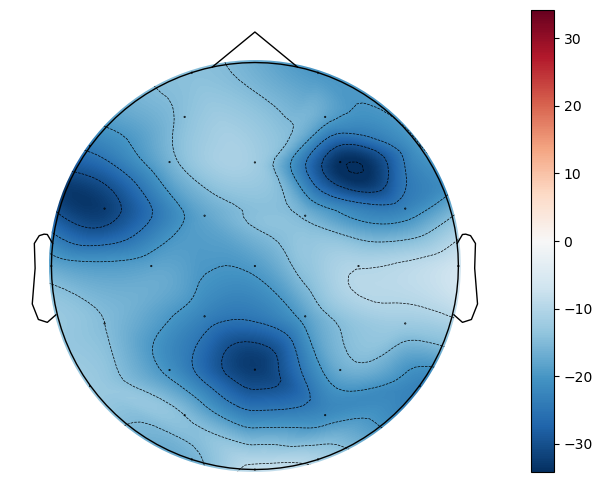

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP008_norm_right_left_preprestim
SP010
['SP010_AttentionTask+004.bdf', 'SP010_AttentionTask+002.bdf', 'SP010_AttentionTask+003.bdf', 'SP010_AttentionTask+001.bdf', 'SP010_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP010_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 2244607  =      0.000 ...   137.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
16 events found on stim channel Status
Event IDs: [ 4  5

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


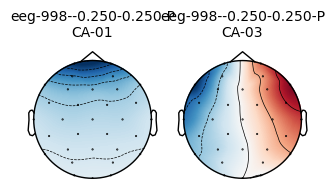

Approximating Fpz location by mirroring Oz along the X and Y axes.


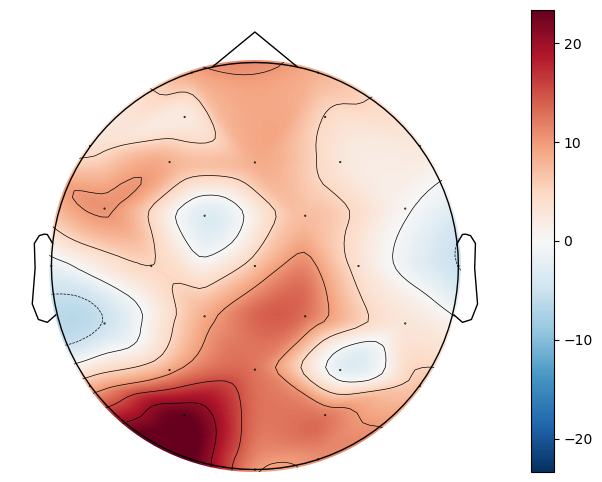

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP010_norm_right_left_preprestim
SP012
['SP012_Attention.bdf', 'SP012_Attention+004.bdf', 'SP012_Attention+003.bdf', 'SP012_Attention+002.bdf', 'SP012_Attention+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP012_Attention.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
104 events found on stim channel Status
Event IDs: [  2   3   4   5   7   8   9  10

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


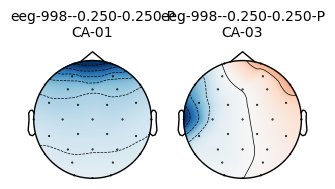

Approximating Fpz location by mirroring Oz along the X and Y axes.


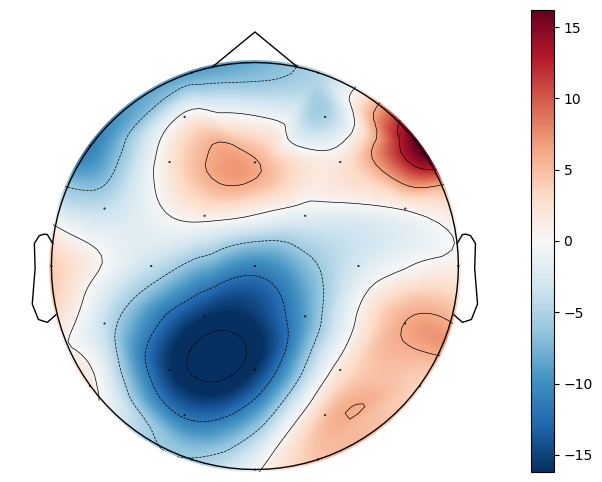

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP012_norm_right_left_preprestim
SP013
['SP013_Attention+003.bdf', 'SP013_Attention+002.bdf', 'SP013_Attention+001.bdf', 'SP013_Attention+004.bdf', 'SP013_Attention.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP013_Attention+003.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
103 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Runnin

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


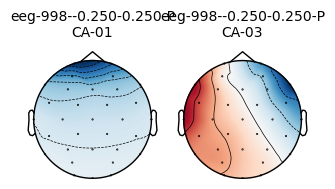

Approximating Fpz location by mirroring Oz along the X and Y axes.


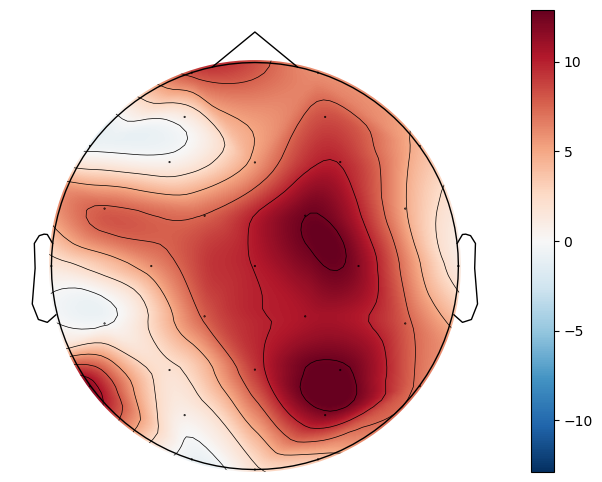

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP013_norm_right_left_preprestim
SP014
['SP014_AttentionTask.bdf', 'SP014_AttentionTask+004.bdf', 'SP014_AttentionTask+002.bdf', 'SP014_AttentionTask+003.bdf', 'SP014_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP014_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
93 events found on stim channel Status
Event IDs: [  3   4 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


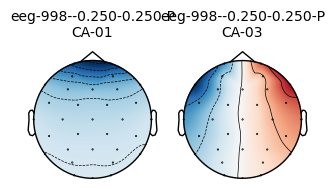

Approximating Fpz location by mirroring Oz along the X and Y axes.


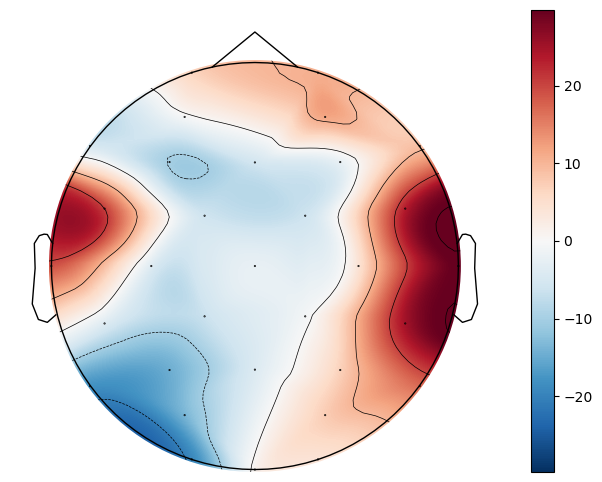

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP014_norm_right_left_preprestim
SP016
['SP016_Attention.bdf', 'SP016_Attention+001.bdf', 'SP016_Attention+003.bdf', 'SP016_Attention+002.bdf', 'SP016_Attention+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP016_Attention.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
70 events found on stim channel Status
Event IDs: [  3   4   5   7   8   9  10  11 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


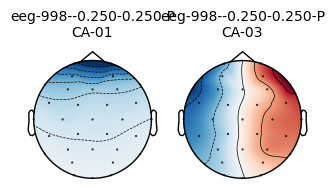

Approximating Fpz location by mirroring Oz along the X and Y axes.


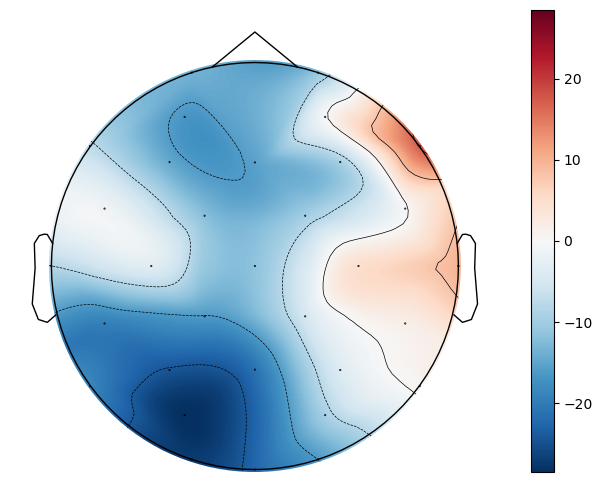

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP016_norm_right_left_preprestim
SP019
['SP019_AttentionTask.bdf', 'SP019_AttentionTask+004.bdf', 'SP019_AttentionTask+005.bdf', 'SP019_AttentionTask+006.bdf', 'SP019_AttentionTask+002.bdf', 'SP019_AttentionTask+003.bdf', 'SP019_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP019_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 7454719  =      0.000 ...   455.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.


/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
44 events found on stim channel Status
Event IDs: [  1   2   3   4   7   8   9  10  11 253]
Running file: SP019_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband att

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
79 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP019_AttentionTask+004.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower

...

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
69 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: SP019_AttentionTask+003.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lo

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
74 events found on stim channel Status
Event IDs: [ 2  3  4  5  6  7  8  9 10 11]
Running file: SP019_AttentionTask+001.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuatio

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


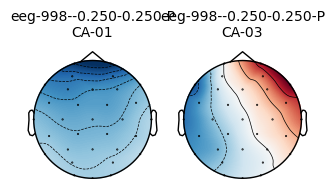

Approximating Fpz location by mirroring Oz along the X and Y axes.


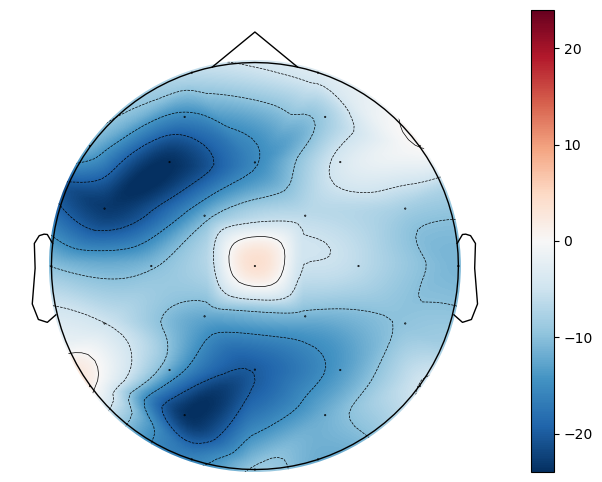

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP019_norm_right_left_preprestim
SP017
['SP017_Attention+004.bdf', 'SP017_Attention+001.bdf', 'SP017_Attention+003.bdf', 'SP017_Attention+002.bdf', 'SP017_Attention.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP017_Attention+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 3440639  =      0.000 ...   210.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
39 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 11]
Running fi

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


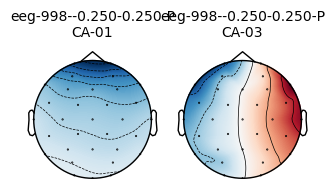

Approximating Fpz location by mirroring Oz along the X and Y axes.


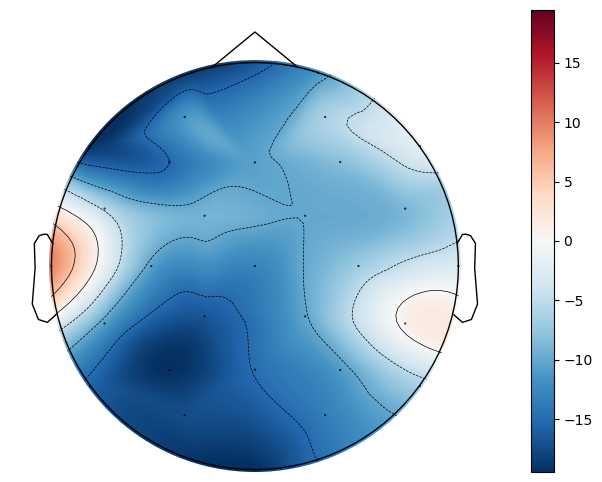

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP017_norm_right_left_preprestim
HL017
['HL017_AttentionTask.bdf', 'HL017_AttentionTask+004.bdf', 'HL017_AttentionTask+002.bdf', 'HL017_AttentionTask+003.bdf', 'HL017_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL017_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
101 events found on stim channel Status
Event IDs: [  3   4

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


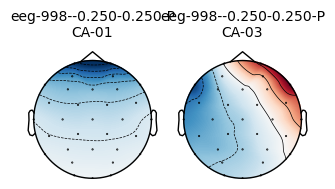

Approximating Fpz location by mirroring Oz along the X and Y axes.


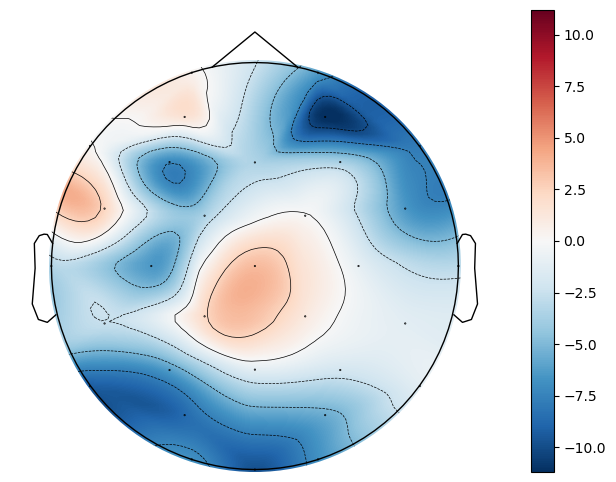

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL017_norm_right_left_preprestim
HL029
['HL029_AttentionTask+005.bdf', 'HL029_AttentionTask+004.bdf', 'HL029_AttentionTask+001.bdf', 'HL029_AttentionTask+003.bdf', 'HL029_AttentionTask+002.bdf', 'HL029_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL029_AttentionTask+005.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1671167  =      0.000 ...   102.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
13 events found on stim c

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


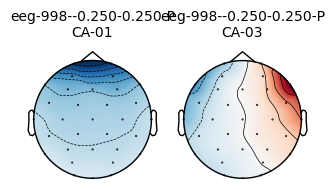

Approximating Fpz location by mirroring Oz along the X and Y axes.


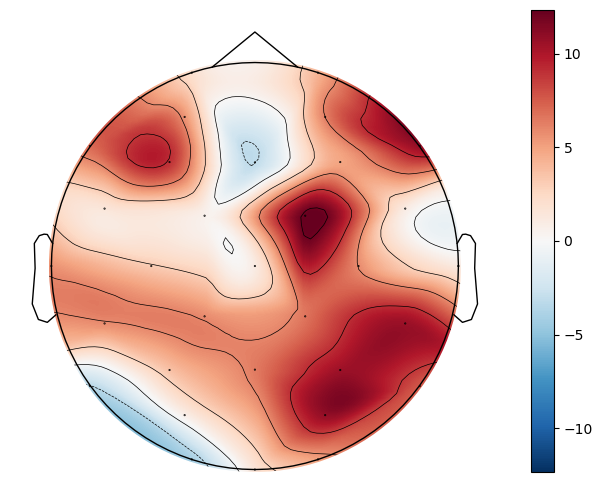

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL029_norm_right_left_preprestim
HL036
['HL036_AttentionTask+001.bdf', 'HL036_AttentionTask+002.bdf', 'HL036_AttentionTask+003.bdf', 'HL036_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL036_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
96 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


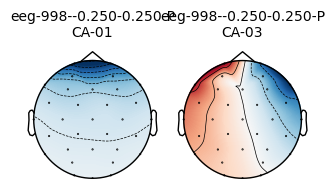

Approximating Fpz location by mirroring Oz along the X and Y axes.


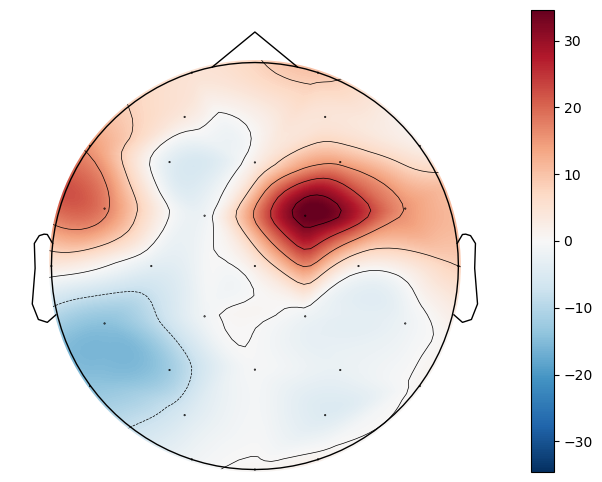

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL036_norm_right_left_preprestim
HR
['HR_Attention+005.bdf', 'HR_Attention+004.bdf', 'HR_Attention+001.bdf', 'HR_Attention+003.bdf', 'HR_Attention+002.bdf', 'HR_Attention.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HR_Attention+005.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
97 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Runn

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5599/3911125969.py:195: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


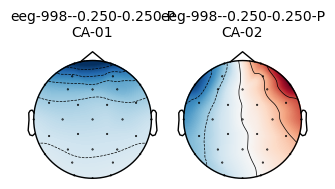

Approximating Fpz location by mirroring Oz along the X and Y axes.


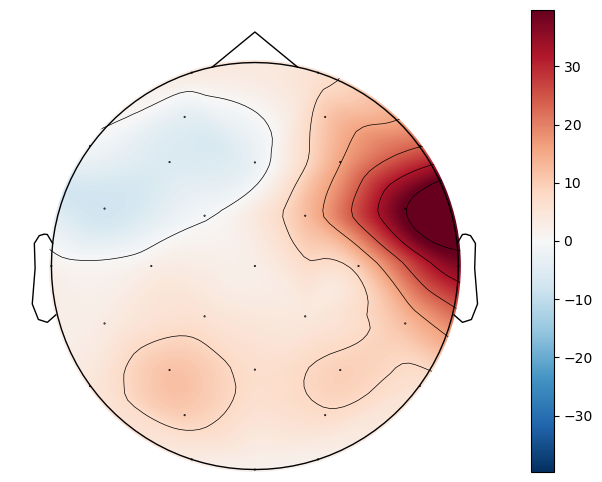

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HR_norm_right_left_preprestim


In [ ]:
import mne
from anlffr.helper import biosemi2mne as bs
from anlffr.preproc import find_blinks
from matplotlib import pyplot as plt
from mne import compute_proj_epochs
from mne import concatenate_epochs
import pylab as pl
import numpy as np
import os
import fnmatch
from scipy.fft import fft
from scipy.signal import find_peaks
import gc 

resultsdir = 'results/'
foldername = '/Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/Figures/evoked_alpha'

HL_subjects = ['HL002', 'HL004', 'HL005', 'HL007', 'HL008', 'HL011', 'HL018', 'HL023', 'HL025', 'HL031', 'HL040', 'HL045', 'HL046', 'HL048', 'HL049', 'HL047', 'HL050']
# HL_subjects = ['HL021']
NH_subjects = ['SP003', 'SP004', 'SP005', 'SP006', 'SP007', 'SP008' , 'SP010', 'SP012', 'SP013', 'SP014','SP016', 'SP019','SP017', 'HL017', 'HL029', 'HL036', 'HR']

subjects = HL_subjects + NH_subjects

# subjects = ['HL010']

left_elecs  = ['Fp1', 'AF3', 'F7', 'F3', 'FC1', 'FC5', 'T7', 'C3', 'CP1', 'CP5', 'P7', 'P3', 'PO3', 'O1']
right_elecs = ['Fp2', 'AF4', 'F8', 'F4', 'FC2', 'FC6', 'T8', 'C4', 'CP2', 'CP6', 'P8', 'P4', 'PO4', 'O2']

freqs    = np.arange(6., 14., 1.)
n_cycles = freqs / 2.0

print(subjects)

fpath = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/'

print(fpath)

for subj in subjects:
    print(subj)
    leads = []
    lags = []
    lefts = []
    rights = []

    event_counts = {2: 0, 3: 0, 4: 0, 5: 0, 6: 0}
    channels_to_drop = ['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']

    bdfs = fnmatch.filter(os.listdir(fpath), subj + '_Att*.bdf')
    
    if subj == 'HL047':
        bdfs = ['HL047_Attention+003.bdf', 'HL047_Attention+002.bdf', 'HL047_Attention.bdf', 'HL047_Attention+001.bdf', 'HL047_Attention+004.bdf']
    if subj == 'HR':
        bdfs = ['HR_Attention+005.bdf', 'HR_Attention+004.bdf', 'HR_Attention+001.bdf', 'HR_Attention+003.bdf', 'HR_Attention+002.bdf', 'HR_Attention.bdf']
    if subj == 'SP003':
        bdfs = ['SP003_Attention_Task+001.bdf', 'SP003_Attention_Task+002.bdf', 'SP003_Attention_Task+003.bdf', 'SP003_Attention_Task+004.bdf', 'SP003_Attention_Task+005.bdf']
    if subj == 'HL012':
        bdfs = ['HL012_AttentionTask.bdf', 'HL012_AttentionTask+004.bdf', 'HL012_AttentionTask+005.bdf', 'HL012_AttentionTask+006.bdf', 'HL012_AttentionTask+002.bdf', 'HL012_AttentionTask+003.bdf', 'HL012_AttentionTask+001.bdf']
    if subj == 'HL025':
        bdfs = ['HL025_AttentionTask+002.bdf', 'HL025_AttentionTask+003.bdf', 'HL025_AttentionTask+004.bdf']
    if subj == 'HL036':
        bdfs = ['HL036_AttentionTask+001.bdf', 'HL036_AttentionTask+002.bdf', 'HL036_AttentionTask+003.bdf', 'HL036_AttentionTask+004.bdf']
    if subj == 'SP014':
        bdfs = ['SP014_AttentionTask.bdf', 'SP014_AttentionTask+004.bdf', 'SP014_AttentionTask+002.bdf', 'SP014_AttentionTask+003.bdf', 'SP014_AttentionTask+001.bdf']
    if subj == 'HL008':
        bdfs = ['HL008_AttentionTask+004.bdf', 'HL008_AttentionTask+003.bdf', 'HL008_AttentionTask+002.bdf', 'HL008_AttentionTask+001.bdf', 'HL008_AttentionTask.bdf']
        ###ABR has been recorded with the same name as Attention - check to make sure it's written somewhere 
    print(bdfs)

    for k, bdf in enumerate(bdfs):
        if bdf == 'HL008_AttentionTask+004.bdf':
            bdf_fullpath = os.path.join(fpath, bdf)
            raw, eves = bs.importbdf(bdf_fullpath, hptsname='/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/biosemi10_20.hpts')
            raw.info['bads'] += ['EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
            total = raw.times[-1]
            end_time = total - 120
            raw = raw.crop(tmin=0, tmax=end_time)
        else:
            bdf_fullpath = os.path.join(fpath, bdf)
            raw, eves = bs.importbdf(bdf_fullpath, hptsname='/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/biosemi10_20.hpts')
            raw.info['bads'] += ['EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
        print(f'Running file: {bdf}')
        raw.notch_filter(
            np.arange(60, 241, 60),
            filter_length='auto',
            fir_design='firwin',
            method='fir'
        )
        raw.filter(1., 40., fir_design='firwin')

        if subj == 'SP004' or subj == 'SP019':
            raw.drop_channels(channels_to_drop)

        blinks = find_blinks(raw, ch_name=['Fp1'])

        if subj in ['HR', 'SP004', 'HL004', 'HL007', 'HL010', 'HL022', 'HL031']:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=2)
            
            raw.add_proj(blink_proj)
            # raw.del_proj(idx=[1])
            raw.apply_proj()
        
        elif subj in ['HL022']:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=4)
            
            raw.add_proj(blink_proj)
            raw.del_proj(idx=[1,2])
            raw.apply_proj()

        else:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=3)
            
            raw.add_proj(blink_proj)
            raw.del_proj(idx=[1])
            raw.apply_proj()
            
        for event_id in [2, 3, 4, 5, 6]:
            event_counts[event_id] += np.sum(eves[:, 2] == event_id)

        events_left = [7,8] 
        events_right = [9,10]
        events_lead = [7,9]
        events_lag = [8,10]

        cue_ids = np.array([7, 8, 9, 10])
        resp_ids = np.array([3, 4, 5])

        cue_idx = np.where(np.isin(eves[:, 2], cue_ids))[0]

        keep_cue_idx = []
        for i in cue_idx:
            after = eves[i+1:]
            resp_pos = np.where(np.isin(after[:, 2], resp_ids))[0]
            if len(resp_pos) == 0:
                continue 
            first_resp_code = after[resp_pos[0], 2]
            if first_resp_code in [1,2,3,4,5,6]:
                keep_cue_idx.append(i)


        eves_cue_resp5 = eves[keep_cue_idx]

        events_left  = [7, 8]
        events_right = [9, 10]
        events_lead  = [7, 9]
        events_lag   = [8, 10]

        def events_present(events, eves):
            return [e for e in events if e in eves[:, 2]]

        events_left_use  = events_present(events_left,  eves_cue_resp5)
        events_right_use = events_present(events_right, eves_cue_resp5)
        events_lead_use  = events_present(events_lead,  eves_cue_resp5)
        events_lag_use   = events_present(events_lag,   eves_cue_resp5)
            
        if events_left_use:
            epochs_left = mne.Epochs(raw, eves_cue_resp5, event_id=events_left_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_right_use:
            epochs_right = mne.Epochs(raw, eves_cue_resp5, event_id=events_right_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_lead_use:
            epochs_lead = mne.Epochs(raw, eves_cue_resp5, event_id=events_lead_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_lag_use:
            epochs_lag = mne.Epochs(raw, eves_cue_resp5, event_id=events_lag_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
            
        if events_left_use:
            lefts.append(epochs_left)

        if events_right_use:
            rights.append(epochs_right)

        if events_lead_use:
            leads.append(epochs_lead)

        if events_lag_use:
            lags.append(epochs_lag)

    left  = mne.concatenate_epochs(lefts,  on_mismatch="ignore") if lefts  else None
    right = mne.concatenate_epochs(rights, on_mismatch="ignore") if rights else None
    lead  = mne.concatenate_epochs(leads,  on_mismatch="ignore") if leads  else None
    lag   = mne.concatenate_epochs(lags,   on_mismatch="ignore") if lags   else None

    for event_id, count in event_counts.items():
        print(f"{event_id}: {count} ")

    raw.plot_projs_topomap(sphere='eeglab')
    plt.show()

    epoch_left_pre = left.crop(tmin=-0.2, tmax=1.8)
    epoch_right_pre = right.crop(tmin=-0.2, tmax=1.8)

    power_alpha_left_pre = epoch_left_pre.compute_tfr(method="multitaper", freqs=freqs, picks=['eeg'], return_itc=False, n_cycles=n_cycles)
    power_alpha_right_pre = epoch_right_pre.compute_tfr(method="multitaper", freqs=freqs, picks=['eeg'], return_itc=False, n_cycles=n_cycles)

    # fname_pleft_pre = fpath+resultsdir+subj+ '_left_alpha_prestim_tfr.h5'    
    # fname_pright_pre = fpath+resultsdir+subj+ '_right_alpha_prestim_tfr.h5'

    # power_alpha_left_pre.save(fname_pleft_pre, overwrite=True)
    # power_alpha_right_pre.save(fname_pright_pre, overwrite=True)

    # power_alpha_left_pre.apply_baseline(baseline=(-0.2, 0.0),  mode='ratio')
    # power_alpha_right_pre.apply_baseline(baseline=(-0.2, 0.0), mode='ratio')

    power_alpha_left_pre.crop(tmin=0.4, tmax=1.6)
    power_alpha_right_pre.crop(tmin=0.4, tmax=1.6)

    avg_power_alpha_left_pre = power_alpha_left_pre.data.mean(axis=0).mean(axis=1).mean(axis=1)
    avg_power_alpha_right_pre = power_alpha_right_pre.data.mean(axis=0).mean(axis=1).mean(axis=1)

    norm_avg_power_alpha_right_left_pre = ((avg_power_alpha_right_pre - avg_power_alpha_left_pre)*200)/\
            (avg_power_alpha_left_pre + avg_power_alpha_right_pre) 

    channels = ['Fp1','AF3','F7','F3','FC1','FC5','T7','C3','CP1','CP5','P7','P3','Pz','PO3',
                    'O1','Oz','O2','PO4','P4','P8','CP6','CP2','C4','T8','FC6','FC2','F4','F8','AF4','Fp2','Fz','Cz']
    info_picked = mne.pick_info(epoch_left_pre.info, mne.pick_channels(epoch_left_pre.info['ch_names'], include =channels))

    fig, ax = plt.subplots(figsize=(8, 6))
    im,_ = mne.viz.plot_topomap(norm_avg_power_alpha_right_left_pre, info_picked, sphere='eeglab', axes=ax, ch_type='eeg',show=False)
    plt.colorbar(im, ax=ax)
    plt.show()

    fname_left_right_pre = fpath+resultsdir+subj+ '_norm_right_left_preprestim' #'_norm_right_left_preprestim'
    print(fname_left_right_pre)
    np.save(fname_left_right_pre, norm_avg_power_alpha_right_left_pre)

    del left, right, lead, lag
    gc.collect()
    del epoch_left_pre, epoch_right_pre, power_alpha_left_pre, power_alpha_right_pre
    gc.collect()
    del avg_power_alpha_left_pre, avg_power_alpha_right_pre, norm_avg_power_alpha_right_left_pre
    gc.collect()

### HL021, HL047 for 3,4,5
### And HL047

['HL047']
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/
HL047
['HL047_Attention+003.bdf', 'HL047_Attention+002.bdf', 'HL047_Attention.bdf', 'HL047_Attention+001.bdf', 'HL047_Attention+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL047_Attention+003.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
107 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: HL047_Attention+003.bd

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_10066/3274583057.py:196: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_10066/3274583057.py:196: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_10066/3274583057.py:196: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_10066/3274583057.py:196: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


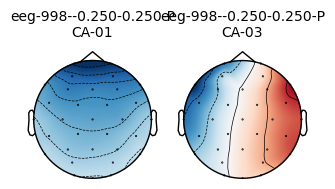

Approximating Fpz location by mirroring Oz along the X and Y axes.


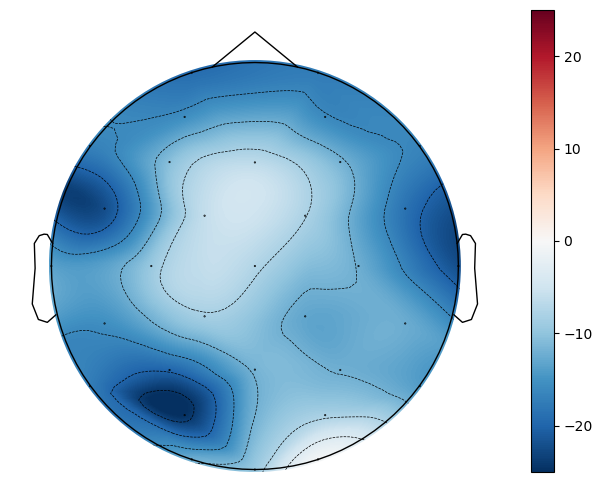

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL047_norm_right_left_preprestim


In [1]:
import mne
from anlffr.helper import biosemi2mne as bs
from anlffr.preproc import find_blinks
from matplotlib import pyplot as plt
from mne import compute_proj_epochs
from mne import concatenate_epochs
import pylab as pl
import numpy as np
import os
import fnmatch
from scipy.fft import fft
from scipy.signal import find_peaks
import gc 

resultsdir = 'results/'
foldername = '/Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/Figures/evoked_alpha'

# HL_subjects = ['HL002', 'HL004', 'HL005', 'HL007', 'HL008', 'HL011', 'HL018', 'HL023', 'HL025', 'HL031', 'HL040', 'HL045', 'HL046', 'HL048', 'HL049', 'HL047', 'HL050']
# NH_subjects = ['SP003', 'SP004', 'SP005', 'SP006', 'SP007', 'SP008' , 'SP010', 'SP012', 'SP013', 'SP014','SP016', 'SP019','SP017', 'HL017', 'HL029', 'HL036', 'HR']

# subjects = HL_subjects + NH_subjects

subjects = ['HL047']

left_elecs  = ['Fp1', 'AF3', 'F7', 'F3', 'FC1', 'FC5', 'T7', 'C3', 'CP1', 'CP5', 'P7', 'P3', 'PO3', 'O1']
right_elecs = ['Fp2', 'AF4', 'F8', 'F4', 'FC2', 'FC6', 'T8', 'C4', 'CP2', 'CP6', 'P8', 'P4', 'PO4', 'O2']

freqs    = np.arange(6., 13., 1.)
n_cycles = freqs / 2.0

print(subjects)

fpath = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/'

print(fpath)

for subj in subjects:
    print(subj)
    leads = []
    lags = []
    lefts = []
    rights = []

    event_counts = {2: 0, 3: 0, 4: 0, 5: 0, 6: 0}
    channels_to_drop = ['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']

    bdfs = fnmatch.filter(os.listdir(fpath), subj + '_Att*.bdf')
    
    if subj == 'HL047':
        bdfs = ['HL047_Attention+003.bdf', 'HL047_Attention+002.bdf', 'HL047_Attention.bdf', 'HL047_Attention+001.bdf', 'HL047_Attention+004.bdf']
    if subj == 'HR':
        bdfs = ['HR_Attention+006.bdf','HR_Attention+005.bdf', 'HR_Attention+004.bdf', 'HR_Attention+001.bdf', 'HR_Attention+003.bdf', 'HR_Attention+002.bdf', 'HR_Attention.bdf']
    if subj == 'SP003':
        bdfs = ['SP003_Attention_Task+001.bdf', 'SP003_Attention_Task+002.bdf', 'SP003_Attention_Task+003.bdf', 'SP003_Attention_Task+004.bdf', 'SP003_Attention_Task+005.bdf']
    if subj == 'HL012':
        bdfs = ['HL012_AttentionTask.bdf', 'HL012_AttentionTask+004.bdf', 'HL012_AttentionTask+005.bdf', 'HL012_AttentionTask+006.bdf', 'HL012_AttentionTask+002.bdf', 'HL012_AttentionTask+003.bdf', 'HL012_AttentionTask+001.bdf']
    if subj == 'HL025':
        bdfs = ['HL025_AttentionTask+002.bdf', 'HL025_AttentionTask+003.bdf', 'HL025_AttentionTask+004.bdf']
    if subj == 'HL036':
        bdfs = ['HL036_AttentionTask+001.bdf', 'HL036_AttentionTask+002.bdf', 'HL036_AttentionTask+003.bdf', 'HL036_AttentionTask+004.bdf']
    if subj == 'SP014':
        bdfs = ['SP014_AttentionTask.bdf', 'SP014_AttentionTask+004.bdf', 'SP014_AttentionTask+002.bdf', 'SP014_AttentionTask+003.bdf', 'SP014_AttentionTask+001.bdf']
    if subj == 'HL008':
        bdfs = ['HL008_AttentionTask+004.bdf', 'HL008_AttentionTask+003.bdf', 'HL008_AttentionTask+002.bdf', 'HL008_AttentionTask+001.bdf', 'HL008_AttentionTask.bdf']
        ###ABR has been recorded with the same name as Attention - check to make sure it's written somewhere 
    print(bdfs)

    for k, bdf in enumerate(bdfs):
        if bdf == 'HL008_AttentionTask+004.bdf':
            bdf_fullpath = os.path.join(fpath, bdf)
            raw, eves = bs.importbdf(bdf_fullpath, hptsname='/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/biosemi10_20.hpts')
            raw.info['bads'] += ['EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
            total = raw.times[-1]
            end_time = total - 120
            raw = raw.crop(tmin=0, tmax=end_time)
        else:
            bdf_fullpath = os.path.join(fpath, bdf)
            raw, eves = bs.importbdf(bdf_fullpath, hptsname='/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/biosemi10_20.hpts')
            raw.info['bads'] += ['EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
        print(f'Running file: {bdf}')
        raw.notch_filter(
            np.arange(60, 241, 60),
            filter_length='auto',
            fir_design='firwin',
            method='fir'
        )
        raw.filter(1., 40., fir_design='firwin')

        if subj == 'SP004' or subj == 'SP019':
            raw.drop_channels(channels_to_drop)

        blinks = find_blinks(raw, ch_name=['Fp1'])

        if subj in ['HR', 'SP004', 'HL004', 'HL007', 'HL010', 'HL022', 'HL031']:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=2)
            
            raw.add_proj(blink_proj)
            # raw.del_proj(idx=[1])
            raw.apply_proj()
        
        elif subj in ['HL022']:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=4)
            
            raw.add_proj(blink_proj)
            raw.del_proj(idx=[1,2])
            raw.apply_proj()

        else:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=3)
            
            raw.add_proj(blink_proj)
            raw.del_proj(idx=[1])
            raw.apply_proj()
            
        for event_id in [2, 3, 4, 5, 6]:
            event_counts[event_id] += np.sum(eves[:, 2] == event_id)

        events_left = [7,8] 
        events_right = [9,10]
        events_lead = [7,9]
        events_lag = [8,10]

        cue_ids = np.array([7, 8, 9, 10])
        resp_ids = np.array([3, 4, 5])

        cue_idx = np.where(np.isin(eves[:, 2], cue_ids))[0]

        keep_cue_idx = []
        for i in cue_idx:
            after = eves[i+1:]
            resp_pos = np.where(np.isin(after[:, 2], resp_ids))[0]
            if len(resp_pos) == 0:
                continue 
            first_resp_code = after[resp_pos[0], 2]
            if first_resp_code in [1,2,3,4,5,6]:
                keep_cue_idx.append(i)


        eves_cue_resp5 = eves[keep_cue_idx]

        events_left  = [7, 8]
        events_right = [9, 10]
        events_lead  = [7, 9]
        events_lag   = [8, 10]

        def events_present(events, eves):
            return [e for e in events if e in eves[:, 2]]

        events_left_use  = events_present(events_left,  eves_cue_resp5)
        events_right_use = events_present(events_right, eves_cue_resp5)
        events_lead_use  = events_present(events_lead,  eves_cue_resp5)
        events_lag_use   = events_present(events_lag,   eves_cue_resp5)
            
        if events_left_use:
            epochs_left = mne.Epochs(raw, eves_cue_resp5, event_id=events_left_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_right_use:
            epochs_right = mne.Epochs(raw, eves_cue_resp5, event_id=events_right_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_lead_use:
            epochs_lead = mne.Epochs(raw, eves_cue_resp5, event_id=events_lead_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_lag_use:
            epochs_lag = mne.Epochs(raw, eves_cue_resp5, event_id=events_lag_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
            
        if events_left_use:
            lefts.append(epochs_left)

        if events_right_use:
            rights.append(epochs_right)

        if events_lead_use:
            leads.append(epochs_lead)

        if events_lag_use:
            lags.append(epochs_lag)

    left  = mne.concatenate_epochs(lefts,  on_mismatch="ignore") if lefts  else None
    right = mne.concatenate_epochs(rights, on_mismatch="ignore") if rights else None
    lead  = mne.concatenate_epochs(leads,  on_mismatch="ignore") if leads  else None
    lag   = mne.concatenate_epochs(lags,   on_mismatch="ignore") if lags   else None

    for event_id, count in event_counts.items():
        print(f"{event_id}: {count} ")

    raw.plot_projs_topomap(sphere='eeglab')
    plt.show()

    epoch_left_pre = left.crop(tmin=-0.2, tmax=1.8)
    epoch_right_pre = right.crop(tmin=-0.2, tmax=1.8)

    power_alpha_left_pre = epoch_left_pre.compute_tfr(method="multitaper", freqs=freqs, picks=['eeg'], return_itc=False, n_cycles=n_cycles)
    power_alpha_right_pre = epoch_right_pre.compute_tfr(method="multitaper", freqs=freqs, picks=['eeg'], return_itc=False, n_cycles=n_cycles)

    # fname_pleft_pre = fpath+resultsdir+subj+ '_left_alpha_prestim_tfr.h5'    
    # fname_pright_pre = fpath+resultsdir+subj+ '_right_alpha_prestim_tfr.h5'

    # power_alpha_left_pre.save(fname_pleft_pre, overwrite=True)
    # power_alpha_right_pre.save(fname_pright_pre, overwrite=True)

    # power_alpha_left_pre.apply_baseline(baseline=(-0.2, 0.0),  mode='ratio')
    # power_alpha_right_pre.apply_baseline(baseline=(-0.2, 0.0), mode='ratio')

    power_alpha_left_pre.crop(tmin=0.4, tmax=1.6)
    power_alpha_right_pre.crop(tmin=0.4, tmax=1.6)

    avg_power_alpha_left_pre = power_alpha_left_pre.data.mean(axis=0).mean(axis=1).mean(axis=1)
    avg_power_alpha_right_pre = power_alpha_right_pre.data.mean(axis=0).mean(axis=1).mean(axis=1)

    norm_avg_power_alpha_right_left_pre = ((avg_power_alpha_right_pre - avg_power_alpha_left_pre)*200)/\
            (avg_power_alpha_left_pre + avg_power_alpha_right_pre) 

    channels = ['Fp1','AF3','F7','F3','FC1','FC5','T7','C3','CP1','CP5','P7','P3','Pz','PO3',
                    'O1','Oz','O2','PO4','P4','P8','CP6','CP2','C4','T8','FC6','FC2','F4','F8','AF4','Fp2','Fz','Cz']
    info_picked = mne.pick_info(epoch_left_pre.info, mne.pick_channels(epoch_left_pre.info['ch_names'], include =channels))

    fig, ax = plt.subplots(figsize=(8, 6))
    im,_ = mne.viz.plot_topomap(norm_avg_power_alpha_right_left_pre, info_picked, sphere='eeglab', axes=ax, ch_type='eeg',show=False)
    plt.colorbar(im, ax=ax)
    plt.show()

    fname_left_right_pre = fpath+resultsdir+subj+ '_norm_right_left_preprestim' #'_norm_right_left_preprestim'
    print(fname_left_right_pre)
    np.save(fname_left_right_pre, norm_avg_power_alpha_right_left_pre)

    del left, right, lead, lag
    gc.collect()
    del epoch_left_pre, epoch_right_pre, power_alpha_left_pre, power_alpha_right_pre
    gc.collect()
    del avg_power_alpha_left_pre, avg_power_alpha_right_pre, norm_avg_power_alpha_right_left_pre
    gc.collect()

## Blink Projections 

['SP003', 'SP004', 'SP005', 'SP006', 'SP007', 'SP008', 'SP010', 'SP012', 'SP013', 'SP014', 'SP016', 'SP019', 'HL017', 'HL029', 'HL036', 'HR', 'HL002', 'HL004', 'HL005', 'HL007', 'HL008', 'HL011', 'HL018', 'HL021', 'HL023', 'HL025', 'HL031', 'HL040', 'HL045', 'HL046', 'HL048', 'HL049', 'HL047', 'HL050']
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/
SP003
['SP003_Attention_Task+001.bdf', 'SP003_Attention_Task+002.bdf', 'SP003_Attention_Task+003.bdf', 'SP003_Attention_Task+004.bdf', 'SP003_Attention_Task+005.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP003_Attention_Task+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG chann

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


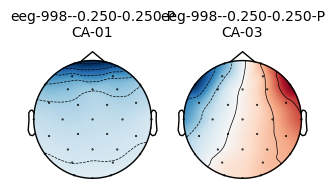

SP004
['SP004_AttentionTaskEEG.bdf', 'SP004_AttentionTaskEEG+004.bdf', 'SP004_AttentionTaskEEG+001.bdf', 'SP004_AttentionTaskEEG+003.bdf', 'SP004_AttentionTaskEEG+002.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP004_AttentionTaskEEG.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 7454719  =      0.000 ...   455.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.


/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
95 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP004_AttentionTaskEEG.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 54069 samples (3.300 s)

Setting up band-pass filter from 0.5 - 10 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.15 Hz (-6 dB cutoff frequency: 0.42 Hz)
- Upper passband edg

...

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
104 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP004_AttentionTaskEEG+003.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- L

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
102 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP004_AttentionTaskEEG+002.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- L

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


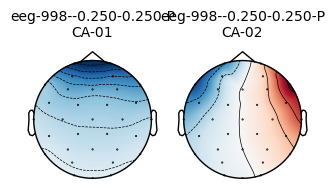

SP005
['SP005_AttentionTaskEEG.bdf', 'SP005_AttentionTaskEEG+001.bdf', 'SP005_AttentionTaskEEG+002.bdf', 'SP005_AttentionTaskEEG+003.bdf', 'SP005_AttentionTaskEEG+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP005_AttentionTaskEEG.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
101 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: SP005_AttentionTaskEEG.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
--------------------

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


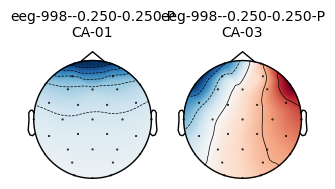

SP006
['SP006_Attentiontask.bdf', 'SP006_Attentiontask+002.bdf', 'SP006_Attentiontask+003.bdf', 'SP006_Attentiontask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP006_Attentiontask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
111 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: SP006_Attentiontask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bands

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


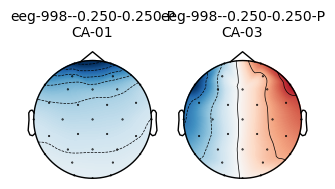

SP007
['SP007_Attentiontask.bdf', 'SP007_Attentiontask+004.bdf', 'SP007_Attentiontask+001.bdf', 'SP007_Attentiontask+002.bdf', 'SP007_Attentiontask+003.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP007_Attentiontask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
94 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP007_Attentiontask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, z

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


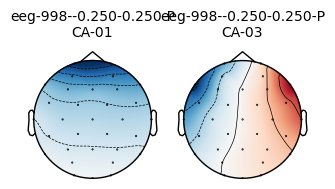

SP008
['SP008_AttentionTask+003.bdf', 'SP008_AttentionTask+002.bdf', 'SP008_AttentionTask+001.bdf', 'SP008_AttentionTask+004.bdf', 'SP008_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP008_AttentionTask+003.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
109 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: SP008_AttentionTask+003.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


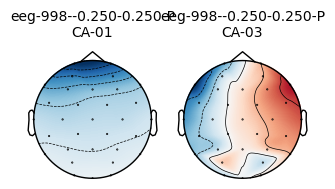

SP010
['SP010_AttentionTask+004.bdf', 'SP010_AttentionTask+002.bdf', 'SP010_AttentionTask+003.bdf', 'SP010_AttentionTask+001.bdf', 'SP010_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP010_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 2244607  =      0.000 ...   137.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
16 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 11]
Running file: SP010_AttentionTask+004.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pas

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


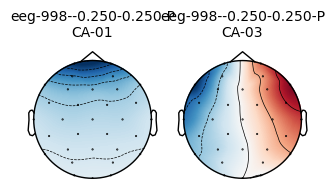

SP012
['SP012_Attention.bdf', 'SP012_Attention+004.bdf', 'SP012_Attention+003.bdf', 'SP012_Attention+002.bdf', 'SP012_Attention+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP012_Attention.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
104 events found on stim channel Status
Event IDs: [  2   3   4   5   7   8   9  10  11 128 253]
Running file: SP012_Attention.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


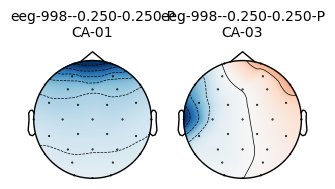

SP013
['SP013_Attention+003.bdf', 'SP013_Attention+002.bdf', 'SP013_Attention+001.bdf', 'SP013_Attention+004.bdf', 'SP013_Attention.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP013_Attention+003.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
103 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP013_Attention+003.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causa

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


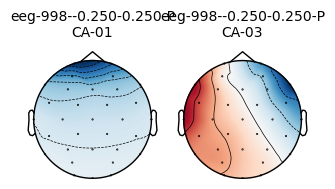

SP014
['SP014_AttentionTask.bdf', 'SP014_AttentionTask+004.bdf', 'SP014_AttentionTask+002.bdf', 'SP014_AttentionTask+003.bdf', 'SP014_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP014_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
93 events found on stim channel Status
Event IDs: [  3   4   5   7   8   9  10  11 253]
Running file: SP014_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designin

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


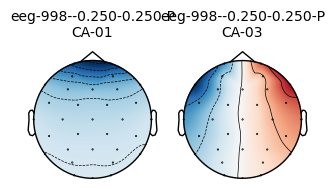

SP016
['SP016_Attention.bdf', 'SP016_Attention+001.bdf', 'SP016_Attention+003.bdf', 'SP016_Attention+002.bdf', 'SP016_Attention+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP016_Attention.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
70 events found on stim channel Status
Event IDs: [  3   4   5   7   8   9  10  11 253]
Running file: SP016_Attention.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, no

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


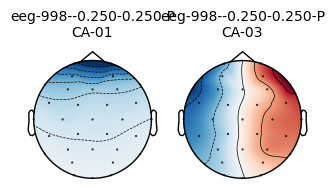

SP019
['SP019_AttentionTask.bdf', 'SP019_AttentionTask+004.bdf', 'SP019_AttentionTask+005.bdf', 'SP019_AttentionTask+006.bdf', 'SP019_AttentionTask+002.bdf', 'SP019_AttentionTask+003.bdf', 'SP019_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP019_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 7454719  =      0.000 ...   455.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.


/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
44 events found on stim channel Status
Event IDs: [  1   2   3   4   7   8   9  10  11 253]
Running file: SP019_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband att

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
79 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP019_AttentionTask+004.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower

...

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
69 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: SP019_AttentionTask+003.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lo

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/helper/biosemi2mne.py:89: RuntimeWarning: DigMontage is only a subset of info. There are 7 channel positions not present in the DigMontage. The channels missing from the montage are:

['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp'].

Consider using inst.rename_channels to match the montage nomenclature, or inst.set_channel_types if these are not EEG channels, or use the on_missing parameter if the channel positions are allowed to be unknown in your analyses.
  raw.set_montage(montage, on_missing='warn')


Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
74 events found on stim channel Status
Event IDs: [ 2  3  4  5  6  7  8  9 10 11]
Running file: SP019_AttentionTask+001.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuatio

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


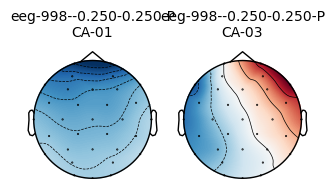

HL017
['HL017_AttentionTask.bdf', 'HL017_AttentionTask+004.bdf', 'HL017_AttentionTask+002.bdf', 'HL017_AttentionTask+003.bdf', 'HL017_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL017_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
101 events found on stim channel Status
Event IDs: [  3   4   5   6   7   8   9  10  11 253]
Running file: HL017_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Des

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


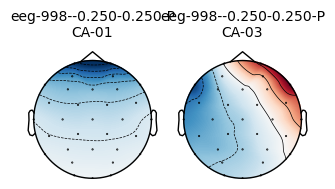

HL029
['HL029_AttentionTask+005.bdf', 'HL029_AttentionTask+004.bdf', 'HL029_AttentionTask+001.bdf', 'HL029_AttentionTask+003.bdf', 'HL029_AttentionTask+002.bdf', 'HL029_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL029_AttentionTask+005.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1671167  =      0.000 ...   102.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
13 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 11]
Running file: HL029_AttentionTask+005.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
----------

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


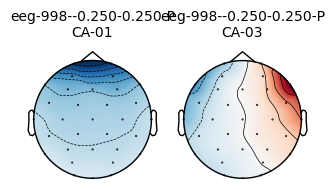

HL036
['HL036_AttentionTask+001.bdf', 'HL036_AttentionTask+002.bdf', 'HL036_AttentionTask+003.bdf', 'HL036_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL036_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
96 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: HL036_AttentionTask+001.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-ca

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


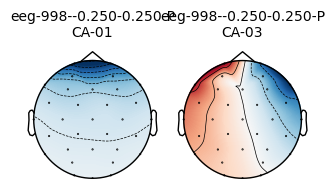

HR
['HR_Attention+006.bdf', 'HR_Attention+007.bdf', 'HR_Attention+005.bdf', 'HR_Attention+004.bdf', 'HR_Attention+001.bdf', 'HR_Attention+003.bdf', 'HR_Attention+002.bdf', 'HR_Attention.bdf', 'HR_Attention+008.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HR_Attention+006.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
103 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: HR_Attention+006.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter p

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


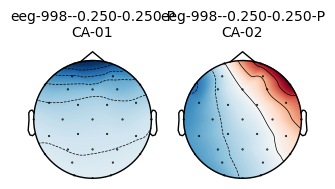

HL002
['HL002_AttentionTask+001.bdf', 'HL002_AttentionTask+003.bdf', 'HL002_AttentionTask+002.bdf', 'HL002_AttentionTask+004.bdf', 'HL002_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL002_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
119 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: HL002_AttentionTask+001.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


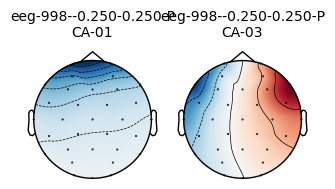

HL004
['HL004_AttentionTask+004.bdf', 'HL004_AttentionTask+002.bdf', 'HL004_AttentionTask+003.bdf', 'HL004_AttentionTask+001.bdf', 'HL004_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL004_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1949695  =      0.000 ...   119.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
20 events found on stim channel Status
Event IDs: [ 5  7  8  9 11]
Running file: HL004_AttentionTask+004.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


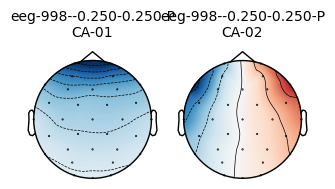

HL005
['HL005_AttentionTask+004.bdf', 'HL005_AttentionTask+005.bdf', 'HL005_AttentionTask+001.bdf', 'HL005_AttentionTask+002.bdf', 'HL005_AttentionTask+003.bdf', 'HL005_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL005_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
91 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: HL005_AttentionTask+004.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
-------

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


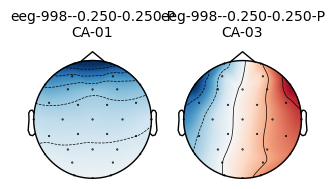

HL007
['HL007_AttentionTask+001.bdf', 'HL007_AttentionTask.bdf', 'HL007_AttentionTask+003.bdf', 'HL007_AttentionTask+002.bdf', 'HL007_AttentionTask+005.bdf', 'HL007_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL007_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
96 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: HL007_AttentionTask+001.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
-------

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


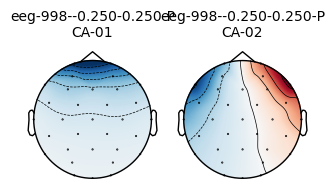

HL008
['HL008_AttentionTask+004.bdf', 'HL008_AttentionTask+003.bdf', 'HL008_AttentionTask+002.bdf', 'HL008_AttentionTask+001.bdf', 'HL008_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL008_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
82 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: HL008_AttentionTask+004.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a o

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


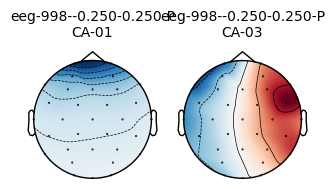

HL011
['HL011_AttentionTask.bdf', 'HL011_AttentionTask+001.bdf', 'HL011_AttentionTask+003.bdf', 'HL011_AttentionTask+002.bdf', 'HL011_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL011_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
96 events found on stim channel Status
Event IDs: [  4   5   7   8   9  10  11 253]
Running file: HL011_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


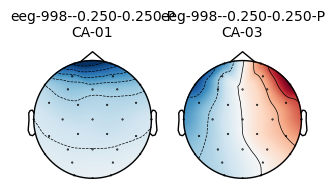

HL018
['HL018_AttentionTask+001.bdf', 'HL018_AttentionTask+003.bdf', 'HL018_AttentionTask+002.bdf', 'HL018_AttentionTask+004.bdf', 'HL018_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL018_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
114 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: HL018_AttentionTask+001.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/preproc.py:58: RuntimeWarning: filter_length (360449) is longer than the signal (294912), distortion is likely. Reduce filter length or filter a longer signal.
  filteog = filter_data(eog, sampling_rate, l_freq, h_freq,


3 projection items deactivated
Created an SSP operator (subspace dimension = 2)
2 projection items activated
SSP projectors applied...
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL018_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
107 events found on stim channel Status
Event IDs: [  5   7   8   9  10  11 253]
Running file: HL018_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


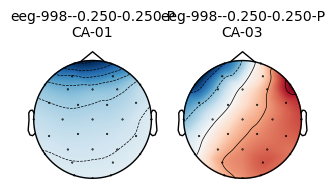

HL021
['HL021_AttentionTask.bdf', 'HL021_AttentionTask+005.bdf', 'HL021_AttentionTask+004.bdf', 'HL021_AttentionTask+003.bdf', 'HL021_AttentionTask+002.bdf', 'HL021_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL021_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
47 events found on stim channel Status
Event IDs: [  1   2   3   7   8   9  10  11 253]
Running file: HL021_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


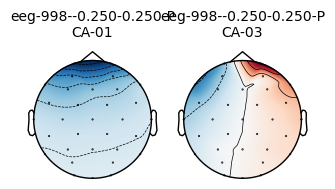

HL023
['HL023_AttentionTask.bdf', 'HL023_AttentionTask+002.bdf', 'HL023_AttentionTask+003.bdf', 'HL023_AttentionTask+001.bdf', 'HL023_AttentionTask+004.bdf', 'HL023_AttentionTask+005.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL023_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
72 events found on stim channel Status
Event IDs: [ 1  2  3  4  5  7  8  9 10 11]
Running file: HL023_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
-----

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


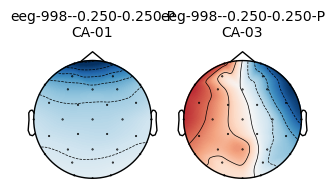

HL025
['HL025_AttentionTask+002.bdf', 'HL025_AttentionTask+003.bdf', 'HL025_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL025_AttentionTask+002.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
100 events found on stim channel Status
Event IDs: [ 2  3  4  5  7  8  9 10 11]
Running file: HL025_AttentionTask+002.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Win

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


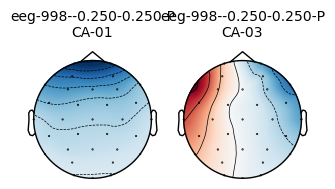

HL031
['HL031_AttentionTask+001.bdf', 'HL031_AttentionTask+002.bdf', 'HL031_AttentionTask.bdf', 'HL031_AttentionTask+003.bdf', 'HL031_AttentionTask+004.bdf', 'HL031_AttentionTask+005.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL031_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
101 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: HL031_AttentionTask+001.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


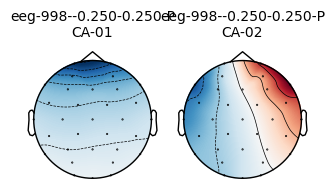

HL040
['HL040_AttentionTask+001.bdf', 'HL040_AttentionTask+002.bdf', 'HL040_AttentionTask+003.bdf', 'HL040_AttentionTask.bdf', 'HL040_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL040_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
95 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: HL040_AttentionTask+001.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


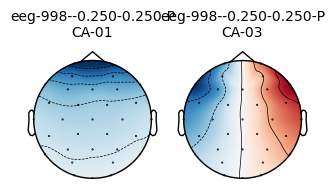

HL045
['HL045_AttentionTask.bdf', 'HL045_AttentionTask+001.bdf', 'HL045_AttentionTask+002.bdf', 'HL045_AttentionTask+003.bdf', 'HL045_AttentionTask+004.bdf', 'HL045_AttentionTask+005.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL045_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
76 events found on stim channel Status
Event IDs: [  2   4   5   6   7   8   9  10  11 253]
Running file: HL045_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parame

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


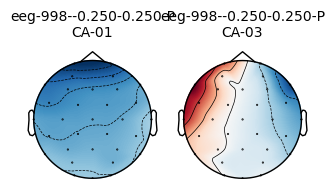

HL046
['HL046_AttentionTask+005.bdf', 'HL046_AttentionTask+004.bdf', 'HL046_AttentionTask+006.bdf', 'HL046_AttentionTask.bdf', 'HL046_AttentionTask+003.bdf', 'HL046_AttentionTask+002.bdf', 'HL046_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL046_AttentionTask+005.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
89 events found on stim channel Status
Event IDs: [ 1  2  3  4  5  7  8  9 10 11]
Running file: HL046_AttentionTask+005.bdf
Filtering raw data in 1 contiguous segment
Setting up band-st

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


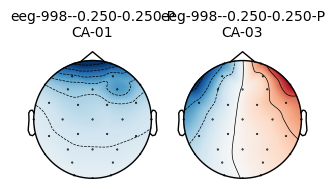

HL048
['HL048_AttentionTask+002.bdf', 'HL048_AttentionTask+003.bdf', 'HL048_AttentionTask+001.bdf', 'HL048_AttentionTask+004.bdf', 'HL048_AttentionTask+005.bdf', 'HL048_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL048_AttentionTask+002.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
90 events found on stim channel Status
Event IDs: [ 2  3  4  5  7  8  9 10 11]
Running file: HL048_AttentionTask+002.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
-

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


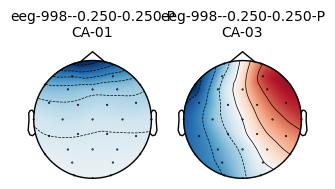

HL049
['HL049_AttentionTask.bdf', 'HL049_AttentionTask+001.bdf', 'HL049_AttentionTask+002.bdf', 'HL049_AttentionTask+003.bdf', 'HL049_AttentionTask+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL049_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
89 events found on stim channel Status
Event IDs: [  4   5   7   8   9  10  11 253]
Running file: HL049_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


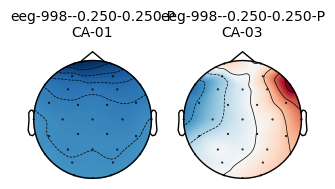

HL047
['HL047_Attention.bdf', 'HL047_Attention+001.bdf', 'HL047_Attention+002.bdf', 'HL047_Attention+003.bdf', 'HL047_Attention+004.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL047_Attention.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
74 events found on stim channel Status
Event IDs: [  1   3   4   5   7   8   9  10  11 253]
Running file: HL047_Attention.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: Runtime

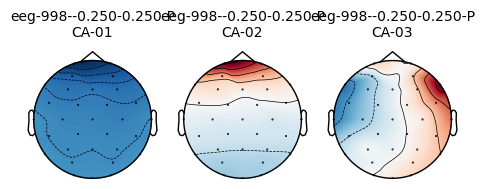

HL050
['HL050_AttentionTask+004.bdf', 'HL050_AttentionTask+003.bdf', 'HL050_AttentionTask+002.bdf', 'HL050_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL050_AttentionTask+004.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
106 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: HL050_AttentionTask+004.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-c

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/4090765678.py:182: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')


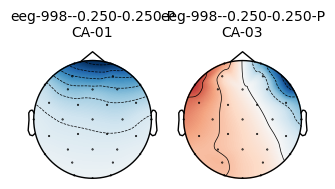

In [ ]:
import mne
from anlffr.helper import biosemi2mne as bs
from anlffr.preproc import find_blinks
from matplotlib import pyplot as plt
from mne import compute_proj_epochs
from mne import concatenate_epochs
import pylab as pl
import numpy as np
import os
import fnmatch
from scipy.fft import fft
from scipy.signal import find_peaks
import gc 

resultsdir = 'results21Apr2026/'
foldername = '/Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/Figures/evoked_alpha'

HL_subjects = ['HL002', 'HL004', 'HL005', 'HL007', 'HL008', 'HL011', 'HL018', 'HL021','HL023', 'HL025', 'HL031', 'HL040', 'HL045', 'HL046', 'HL048', 'HL049', 'HL047', 'HL050']
NH_subjects = ['SP003', 'SP004', 'SP005', 'SP006', 'SP007', 'SP008' , 'SP010', 'SP012', 'SP013', 'SP014','SP016', 'SP019', 'HL017', 'HL029', 'HL036', 'HR']

subjects = NH_subjects + HL_subjects

left_elecs  = ['Fp1', 'AF3', 'F7', 'F3', 'FC1', 'FC5', 'T7', 'C3', 'CP1', 'CP5', 'P7', 'P3', 'PO3', 'O1']
right_elecs = ['Fp2', 'AF4', 'F8', 'F4', 'FC2', 'FC6', 'T8', 'C4', 'CP2', 'CP6', 'P8', 'P4', 'PO4', 'O2']

freqs    = np.arange(6., 14., 1.)
n_cycles = freqs / 2.0

print(subjects)

fpath = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/'

print(fpath)

for subj in subjects:
    print(subj)
    leads = []
    lags = []
    lefts = []
    rights = []

    event_counts = {2: 0, 3: 0, 4: 0, 5: 0, 6: 0}
    channels_to_drop = ['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']

    bdfs = fnmatch.filter(os.listdir(fpath), subj + '_Att*.bdf')
    
    if subj == 'SP003':
        bdfs = ['SP003_Attention_Task+001.bdf', 'SP003_Attention_Task+002.bdf', 'SP003_Attention_Task+003.bdf', 'SP003_Attention_Task+004.bdf', 'SP003_Attention_Task+005.bdf']
    if subj == 'HL012':
        bdfs = ['HL012_AttentionTask.bdf', 'HL012_AttentionTask+004.bdf', 'HL012_AttentionTask+005.bdf', 'HL012_AttentionTask+006.bdf', 'HL012_AttentionTask+002.bdf', 'HL012_AttentionTask+003.bdf', 'HL012_AttentionTask+001.bdf']
    if subj == 'HL025':
        bdfs = ['HL025_AttentionTask+002.bdf', 'HL025_AttentionTask+003.bdf', 'HL025_AttentionTask+004.bdf']
    if subj == 'HL036':
        bdfs = ['HL036_AttentionTask+001.bdf', 'HL036_AttentionTask+002.bdf', 'HL036_AttentionTask+003.bdf', 'HL036_AttentionTask+004.bdf']
    if subj == 'SP014':
        bdfs = ['SP014_AttentionTask.bdf', 'SP014_AttentionTask+004.bdf', 'SP014_AttentionTask+002.bdf', 'SP014_AttentionTask+003.bdf', 'SP014_AttentionTask+001.bdf']
    if subj == 'HL008':
        bdfs = ['HL008_AttentionTask+004.bdf', 'HL008_AttentionTask+003.bdf', 'HL008_AttentionTask+002.bdf', 'HL008_AttentionTask+001.bdf', 'HL008_AttentionTask.bdf']
        ###ABR has been recorded with the same name as Attention - check to make sure it's written somewhere 
    print(bdfs)

    for k, bdf in enumerate(bdfs):
        if bdf == 'HL008_AttentionTask+004.bdf':
            bdf_fullpath = os.path.join(fpath, bdf)
            raw, eves = bs.importbdf(bdf_fullpath, hptsname='/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/biosemi10_20.hpts')
            raw.info['bads'] += ['EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
            total = raw.times[-1]
            end_time = total - 120
            raw = raw.crop(tmin=0, tmax=end_time)
        else:
            bdf_fullpath = os.path.join(fpath, bdf)
            raw, eves = bs.importbdf(bdf_fullpath, hptsname='/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/biosemi10_20.hpts')
            raw.info['bads'] += ['EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
        print(f'Running file: {bdf}')
        raw.notch_filter(
            np.arange(60, 241, 60),
            filter_length='auto',
            fir_design='firwin',
            method='fir'
        )
        raw.filter(1., 40., fir_design='firwin')

        if subj == 'SP004' or subj == 'SP019':
            raw.drop_channels(channels_to_drop)

        blinks = find_blinks(raw, ch_name=['Fp1'])

        # if subj in ['HL047']:
        #     if bdf == 0:
        #         epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
        #                                 reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
        #         blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=1)
        #     raw.add_proj(blink_proj)
        #     raw.apply_proj()

        if subj in ['HR', 'SP004', 'HL004', 'HL007', 'HL010', 'HL022', 'HL031']:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=2)
            
            raw.add_proj(blink_proj)
            # raw.del_proj(idx=[1])
            raw.apply_proj()
        
        elif subj in ['HL022']:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=4)
            
            raw.add_proj(blink_proj)
            raw.del_proj(idx=[1,2])
            raw.apply_proj()

        else:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                        reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=3)
            
            raw.add_proj(blink_proj)
            raw.del_proj(idx=[1])
            raw.apply_proj()
            
        for event_id in [2, 3, 4, 5, 6]:
            event_counts[event_id] += np.sum(eves[:, 2] == event_id)

        events_left = [7,8] 
        events_right = [9,10]
        events_lead = [7,9]
        events_lag = [8,10]

        cue_ids = np.array([7, 8, 9, 10])
        resp_ids = np.array([3, 4, 5])

        cue_idx = np.where(np.isin(eves[:, 2], cue_ids))[0]

        keep_cue_idx = []
        for i in cue_idx:
            after = eves[i+1:]
            resp_pos = np.where(np.isin(after[:, 2], resp_ids))[0]
            if len(resp_pos) == 0:
                continue 
            first_resp_code = after[resp_pos[0], 2]
            if first_resp_code in [2,3,4,5]:
                keep_cue_idx.append(i)


        eves_cue_resp5 = eves[keep_cue_idx]

        events_left  = [7, 8]
        events_right = [9, 10]

        def events_present(events, eves):
            return [e for e in events if e in eves[:, 2]]

        events_left_use  = events_present(events_left,  eves_cue_resp5)
        events_right_use = events_present(events_right, eves_cue_resp5)
            
        if events_left_use:
            epochs_left = mne.Epochs(raw, eves_cue_resp5, event_id=events_left_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_right_use:
            epochs_right = mne.Epochs(raw, eves_cue_resp5, event_id=events_right_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
            
        if events_left_use:
            lefts.append(epochs_left)

        if events_right_use:
            rights.append(epochs_right)


    left  = mne.concatenate_epochs(lefts,  on_mismatch="ignore") if lefts  else None
    right = mne.concatenate_epochs(rights, on_mismatch="ignore") if rights else None


    for event_id, count in event_counts.items():
        print(f"{event_id}: {count} ")

    raw.plot_projs_topomap(sphere='eeglab')
    plt.show()

### check SP012, SP013, HL017, HR, HL018, 
remove 021 from analysis 

['SP012', 'SP013', 'HL017', 'HR', 'HL018']
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/
SP012
['SP012_Attention.bdf', 'SP012_Attention+004.bdf', 'SP012_Attention+003.bdf', 'SP012_Attention+002.bdf', 'SP012_Attention+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP012_Attention.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
104 events found on stim channel Status
Event IDs: [  2   3   4   5   7   8   9 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarni

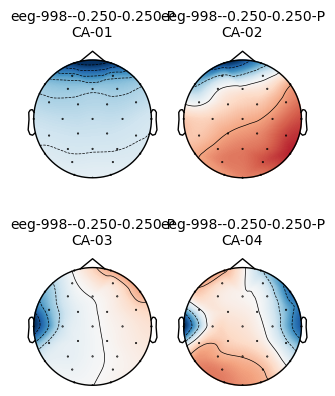

SP013
['SP013_Attention+003.bdf', 'SP013_Attention+002.bdf', 'SP013_Attention+001.bdf', 'SP013_Attention+004.bdf', 'SP013_Attention.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/SP013_Attention+003.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
103 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: SP013_Attention+003.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causa

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarni

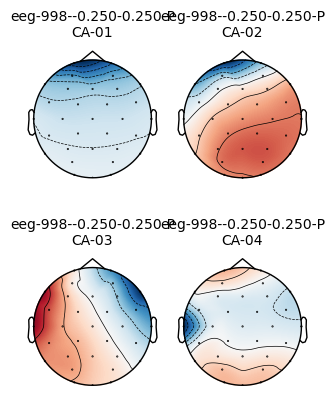

HL017
['HL017_AttentionTask.bdf', 'HL017_AttentionTask+004.bdf', 'HL017_AttentionTask+002.bdf', 'HL017_AttentionTask+003.bdf', 'HL017_AttentionTask+001.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL017_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
101 events found on stim channel Status
Event IDs: [  3   4   5   6   7   8   9  10  11 253]
Running file: HL017_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Des

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarni

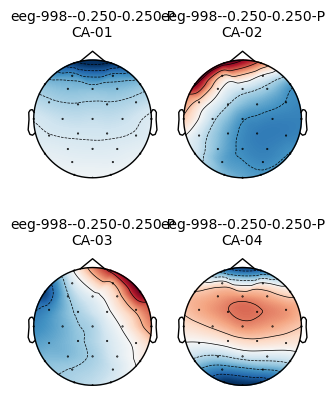

HR
['HR_Attention+006.bdf', 'HR_Attention+007.bdf', 'HR_Attention+005.bdf', 'HR_Attention+004.bdf', 'HR_Attention+001.bdf', 'HR_Attention+003.bdf', 'HR_Attention+002.bdf', 'HR_Attention.bdf', 'HR_Attention+008.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HR_Attention+006.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
103 events found on stim channel Status
Event IDs: [ 3  4  5  7  8  9 10 11]
Running file: HR_Attention+006.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter p

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarni

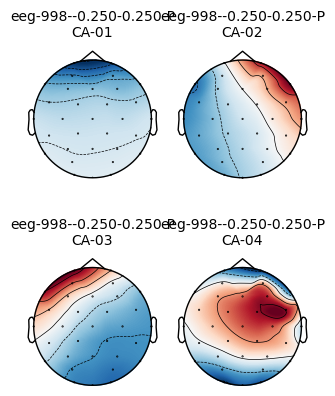

HL018
['HL018_AttentionTask+001.bdf', 'HL018_AttentionTask+003.bdf', 'HL018_AttentionTask+002.bdf', 'HL018_AttentionTask+004.bdf', 'HL018_AttentionTask.bdf']
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL018_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
114 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Running file: HL018_AttentionTask+001.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one

/Users/SHB330/.local/lib/python3.12/site-packages/anlffr/preproc.py:58: RuntimeWarning: filter_length (360449) is longer than the signal (294912), distortion is likely. Reduce filter length or filter a longer signal.
  filteog = filter_data(eog, sampling_rate, l_freq, h_freq,


4 projection items deactivated
Created an SSP operator (subspace dimension = 4)
4 projection items activated
SSP projectors applied...
Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/HL018_AttentionTask.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
107 events found on stim channel Status
Event IDs: [  5   7   8   9  10  11 253]
Running file: HL018_AttentionTask.bdf
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  raw.plot_projs_topomap(sphere='eeglab')
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_4282/521986515.py:183: RuntimeWarni

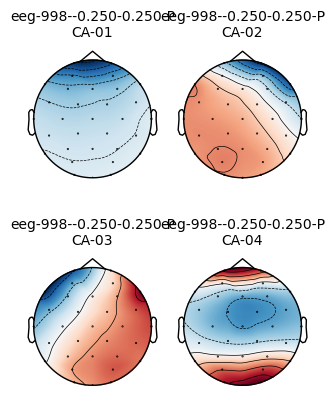

In [ ]:
import mne
from anlffr.helper import biosemi2mne as bs
from anlffr.preproc import find_blinks
from matplotlib import pyplot as plt
from mne import compute_proj_epochs
from mne import concatenate_epochs
import pylab as pl
import numpy as np
import os
import fnmatch
from scipy.fft import fft
from scipy.signal import find_peaks
import gc 

resultsdir = 'results21Apr2026/'
foldername = '/Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/Figures/evoked_alpha'

HL_subjects = ['HL002', 'HL004', 'HL005', 'HL007', 'HL008', 'HL011', 'HL018', 'HL021','HL023', 'HL025', 'HL031', 'HL040', 'HL045', 'HL046', 'HL048', 'HL049', 'HL047', 'HL050']
NH_subjects = ['SP003', 'SP004', 'SP005', 'SP006', 'SP007', 'SP008' , 'SP010', 'SP012', 'SP013', 'SP014','SP016', 'SP019', 'HL017', 'HL029', 'HL036', 'HR']

subjects = NH_subjects + HL_subjects

subjects = ['SP012', 'SP013', 'HL017', 'HR', 'HL018']

left_elecs  = ['Fp1', 'AF3', 'F7', 'F3', 'FC1', 'FC5', 'T7', 'C3', 'CP1', 'CP5', 'P7', 'P3', 'PO3', 'O1']
right_elecs = ['Fp2', 'AF4', 'F8', 'F4', 'FC2', 'FC6', 'T8', 'C4', 'CP2', 'CP6', 'P8', 'P4', 'PO4', 'O2']

freqs    = np.arange(6., 14., 1.)
n_cycles = freqs / 2.0

print(subjects)

fpath = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/'

print(fpath)

for subj in subjects:
    print(subj)
    leads = []
    lags = []
    lefts = []
    rights = []

    event_counts = {2: 0, 3: 0, 4: 0, 5: 0, 6: 0}
    channels_to_drop = ['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']

    bdfs = fnmatch.filter(os.listdir(fpath), subj + '_Att*.bdf')
    
    if subj == 'SP003':
        bdfs = ['SP003_Attention_Task+001.bdf', 'SP003_Attention_Task+002.bdf', 'SP003_Attention_Task+003.bdf', 'SP003_Attention_Task+004.bdf', 'SP003_Attention_Task+005.bdf']
    if subj == 'HL012':
        bdfs = ['HL012_AttentionTask.bdf', 'HL012_AttentionTask+004.bdf', 'HL012_AttentionTask+005.bdf', 'HL012_AttentionTask+006.bdf', 'HL012_AttentionTask+002.bdf', 'HL012_AttentionTask+003.bdf', 'HL012_AttentionTask+001.bdf']
    if subj == 'HL025':
        bdfs = ['HL025_AttentionTask+002.bdf', 'HL025_AttentionTask+003.bdf', 'HL025_AttentionTask+004.bdf']
    if subj == 'HL036':
        bdfs = ['HL036_AttentionTask+001.bdf', 'HL036_AttentionTask+002.bdf', 'HL036_AttentionTask+003.bdf', 'HL036_AttentionTask+004.bdf']
    if subj == 'SP014':
        bdfs = ['SP014_AttentionTask.bdf', 'SP014_AttentionTask+004.bdf', 'SP014_AttentionTask+002.bdf', 'SP014_AttentionTask+003.bdf', 'SP014_AttentionTask+001.bdf']
    if subj == 'HL008':
        bdfs = ['HL008_AttentionTask+004.bdf', 'HL008_AttentionTask+003.bdf', 'HL008_AttentionTask+002.bdf', 'HL008_AttentionTask+001.bdf', 'HL008_AttentionTask.bdf']
        ###ABR has been recorded with the same name as Attention - check to make sure it's written somewhere 
    print(bdfs)

    for k, bdf in enumerate(bdfs):
        if bdf == 'HL008_AttentionTask+004.bdf':
            bdf_fullpath = os.path.join(fpath, bdf)
            raw, eves = bs.importbdf(bdf_fullpath, hptsname='/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/biosemi10_20.hpts')
            raw.info['bads'] += ['EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
            total = raw.times[-1]
            end_time = total - 120
            raw = raw.crop(tmin=0, tmax=end_time)
        else:
            bdf_fullpath = os.path.join(fpath, bdf)
            raw, eves = bs.importbdf(bdf_fullpath, hptsname='/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/biosemi10_20.hpts')
            raw.info['bads'] += ['EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
        print(f'Running file: {bdf}')
        raw.notch_filter(
            np.arange(60, 241, 60),
            filter_length='auto',
            fir_design='firwin',
            method='fir'
        )
        raw.filter(1., 40., fir_design='firwin')

        if subj == 'SP004' or subj == 'SP019':
            raw.drop_channels(channels_to_drop)

        blinks = find_blinks(raw, ch_name=['Fp1'])

        # if subj in ['HL047']:
        #     if bdf == 0:
        #         epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
        #                                 reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
        #         blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=1)
        #     raw.add_proj(blink_proj)
        #     raw.apply_proj()

        # if subj in ['HR', 'SP004', 'HL004', 'HL007', 'HL010', 'HL022', 'HL031']:
        #     if k == 0:
        #         epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
        #                                 reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
        #         blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=2)
            
        #     raw.add_proj(blink_proj)
        #     # raw.del_proj(idx=[1])
        #     raw.apply_proj()
        
        if k == 0:
            epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                    reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
            blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=4)
        
        raw.add_proj(blink_proj)
        # raw.del_proj(idx=[1,2])
        raw.apply_proj()

        # else:
        #     if k == 0:
        #         epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
        #                                 reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
        #         blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=3)
            
        #     raw.add_proj(blink_proj)
        #     raw.del_proj(idx=[1])
        #     raw.apply_proj()
            
        for event_id in [2, 3, 4, 5, 6]:
            event_counts[event_id] += np.sum(eves[:, 2] == event_id)

        events_left = [7,8] 
        events_right = [9,10]
        events_lead = [7,9]
        events_lag = [8,10]

        cue_ids = np.array([7, 8, 9, 10])
        resp_ids = np.array([3, 4, 5])

        cue_idx = np.where(np.isin(eves[:, 2], cue_ids))[0]

        keep_cue_idx = []
        for i in cue_idx:
            after = eves[i+1:]
            resp_pos = np.where(np.isin(after[:, 2], resp_ids))[0]
            if len(resp_pos) == 0:
                continue 
            first_resp_code = after[resp_pos[0], 2]
            if first_resp_code in [2,3,4,5]:
                keep_cue_idx.append(i)


        eves_cue_resp5 = eves[keep_cue_idx]

        events_left  = [7, 8]
        events_right = [9, 10]

        def events_present(events, eves):
            return [e for e in events if e in eves[:, 2]]

        events_left_use  = events_present(events_left,  eves_cue_resp5)
        events_right_use = events_present(events_right, eves_cue_resp5)
            
        if events_left_use:
            epochs_left = mne.Epochs(raw, eves_cue_resp5, event_id=events_left_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
        if events_right_use:
            epochs_right = mne.Epochs(raw, eves_cue_resp5, event_id=events_right_use, baseline=(-0.5, 0.0), proj=True,
                            tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
            
        if events_left_use:
            lefts.append(epochs_left)

        if events_right_use:
            rights.append(epochs_right)


    left  = mne.concatenate_epochs(lefts,  on_mismatch="ignore") if lefts  else None
    right = mne.concatenate_epochs(rights, on_mismatch="ignore") if rights else None


    for event_id, count in event_counts.items():
        print(f"{event_id}: {count} ")

    raw.plot_projs_topomap(sphere='eeglab')
    plt.show()